# Dynamically Growing Neural Networks on MNIST

### An empirical study of neuron-wise and layer-wise network growth, with per-epoch logging of weights, biases and gradients

## Abstract

This notebook has the complete thesis on **dynamically growing neural networks**, in which a network starts with a single hidden neuron and adds capacity during training until its training loss falls below a target value (0.05) or when the maximum epoch limit has been reached. 

Single-hidden-layer networks of fixed width (100, 44 and 20 neurons) are compared with a neuron-wise growing network, and two-hidden-layer fixed networks are compared with a layer-wise growing network that inserts function-preserving identity layers (Net2Net). The growing single-layer network reaches the target with 44 neurons and matches the fixed 44-neuron network in test accuracy at epoch 50 (97.01% vs. 97.06%) while using 57% of its neuron-epochs, and it overfits less. The per-neuron logs reveal that 25% of its neurons are *dead* (permanently inactive). A revival mechanism, introduced in response to this finding, reaches the target with only 38 neurons (97.07% test accuracy, 13.6% fewer parameters). Layer-wise growth is shown to be sensitive to its plateau criterion and to inherit dead neurons through identity initialisation; on MNIST, additional depth provides no benefit.

## Contents

1. Introduction
2. Experimental setup
3. Experiments with one hidden layer (Experiments 1, 2 and 2b)
4. Experiments with several hidden layers (Experiments 3, 4 and 4b)
5. Analysis of the recorded data
6. Results and discussion
7. Conclusions and future work

## 1. Introduction

### 1.1 Background

The size of a neural network is usually chosen by hand before training. A network that is too small underfits; one that is too large wastes computation and tends to overfit. Biological neural systems, by contrast, grow and reorganise in response to the demands placed on them. A **growing neural network** adopts this idea: it begins with minimal capacity and adds neurons (or layers) only when its learning progress shows that more capacity is needed.

The author's thesis (Major Project 2) developed this idea in three stages:

1. a growing network that learns the XOR function, starting from a single hidden neuron;
2. a growing network for MNIST that adds one hidden neuron at a time and **retrains from scratch** after every addition;
3. an optimised version that **preserves the learned weights** when a neuron is added, so that training continues from the current state instead of restarting. On MNIST this version reached a training loss below 0.05 with about 37 hidden neurons.

### 1.2 Objectives

This notebook extends stage 3. The supervisor's protocol requires that, for each scenario below, the values of the weights, biases, gradients and related quantities be **collected for every epoch and every neuron**:

| Scenario | Problem A: one hidden layer | Problem B: more than one hidden layer |
|---|---|---|
| 1 | fixed hidden layer of 100 neurons | two hidden layers of 100 neurons |
| 2 | fixed hidden layer of 44 neurons | two hidden layers of 44 neurons |
| 3 | fixed hidden layer of 20 neurons | two hidden layers of 20 neurons |
| 4 | starts with 1 neuron and grows on the loss (thesis method) | starts with 1 neuron and grows **layer-wise** |

Problem B is studied on MNIST first; CIFAR-10, where depth matters more, is planned as the next stage.

### 1.3 Research questions

- **RQ1.** Does a network grown from a single neuron reach the accuracy of a fixed network of the same final size?
- **RQ2.** How do weights, gradients and neuron activity evolve differently in growing and fixed networks?
- **RQ3.** Does growth affect overfitting?
- **RQ4.** Can whole layers be added without losing what the network has already learned, and does layer-wise growth help on MNIST?
- **RQ5.** *(arose from the recorded data)* Why do growing networks accumulate dead neurons, and can this be prevented?

### 1.4 Changes relative to the thesis implementation

The thesis code was written in Keras. This study re-implements it in PyTorch, which gives direct access to per-batch gradients, and makes the following deliberate changes:

| Aspect | Thesis | This study | Reason |
|---|---|---|---|
| Initial hidden size | 0 neurons | 1 neuron | as specified by the protocol; a 0-neuron layer is degenerate |
| Output layer | sigmoid + sparse categorical cross-entropy | logits + softmax cross-entropy | sigmoid outputs are not a valid probability distribution over 10 classes |
| After the target is reached | training stops | growth stops, training continues to the epoch budget | all runs are compared over the same number of epochs |
| Input scaling | pixels divided by 255 | standardised (mean 0.1307, std 0.3081) | standard practice for MNIST |

## 2. Experimental setup

### 2.1 Dataset

MNIST contains 60,000 training and 10,000 test images of handwritten digits (28 × 28 grey-scale pixels, 10 classes) [4]. Images are standardised with the dataset mean (0.1307) and standard deviation (0.3081). **No data augmentation is used**, because random transformations would add noise to the recorded gradients and make runs harder to compare.

### 2.2 Training configuration

| Setting | Value |
|---|---|
| Framework and hardware | PyTorch [9] on Kaggle, NVIDIA Tesla T4 GPU |
| Hidden activation | ReLU |
| Loss | cross-entropy over 10 output logits |
| Optimiser | Adam [3], learning rate $10^{-3}$; a new optimiser is created after every growth step |
| Batch size | 128 (469 mini-batches per epoch) |
| Epochs | 50 (Experiments 1, 2, 2b, 3); 100 (Experiments 4, 4b) |
| Initialisation | PyTorch default, uniform in $\pm 1/\sqrt{\text{fan-in}}$ |
| Random seed | 42 for every run |
| Growth target | training loss $< 0.05$ |

### 2.3 Experiments

| Exp. | Section | Hidden layers | How the size is determined | Epochs | Run name |
|---|---|---|---|---|---|
| 1 | 3.2 | 1 | fixed: 100 / 44 / 20 neurons | 50 | `mlp_fixed_100`, `mlp_fixed_44`, `mlp_fixed_20` |
| 2 | 3.3 | 1 | grows from 1 neuron (thesis rule) | 50 | `mlp_growing_from_1` |
| 2b | 3.4 | 1 | grows from 1 neuron, with dead-neuron revival | 50 | `mlp_growing_from_1_revive` |
| 3 | 4.1 | 2 | fixed: 100+100 / 44+44 / 20+20 | 50 | `deep_fixed_100x100`, `deep_fixed_44x44`, `deep_fixed_20x20` |
| 4 | 4.2 | up to 3 | layer-wise growth, one-epoch plateau rule | 100 | `deep_growing_layerwise` |
| 4b | 4.3 | up to 3 | layer-wise growth, three-epoch plateau rule | 100 | `deep_growing_layerwise_v2` |

Experiments 2b and 4b were not part of the original protocol. They were added during the study to address problems that the recorded data revealed in Experiments 2 and 4.

### 2.4 Recorded data

After every epoch, the following is written to `/kaggle/working/experiment_logs/<run name>/`:

| File | Content |
|---|---|
| `epoch_XXX.npz` | every weight and bias (`param__<layer>.weight`, `param__<layer>.bias`) and the epoch-averaged gradient of each (`grad__...`) |
| `neuron_stats.csv` | one row per neuron per epoch: bias; mean, standard deviation and L2 norm of the incoming weights; mean and L2 norm of their gradient; bias gradient; mean pre-activation; active rate |
| `epoch_summary.csv` | one row per epoch: layer sizes, training and test loss and accuracy, elapsed time, and the growth decision (growing runs) |
| `final_model.pt`, `final_network.png` | final weights and architecture diagram (growing runs) |

**Definitions.**
- The *epoch-averaged gradient* of a parameter is the mean of its gradient over all 469 mini-batches of the epoch. It describes how the parameter was pushed during the whole epoch, not just by the last batch.
- The *active rate* of a neuron is the fraction of training images for which its pre-activation is positive, i.e. for which ReLU lets its signal through.
- A neuron is called **dead** when its active rate is below 1%. A dead ReLU neuron receives a zero gradient, so ordinary training can never revive it [6].

### 2.5 Reproducibility

The complete notebook ran top to bottom with Kaggle's *Save & Run All* in 88.5 minutes. Two independent runs produced identical figures, so the results are deterministic for the given seed. Re-running requires a GPU and Internet access (MNIST is downloaded on first use).

## 3. Experiments with one hidden layer

### 3.1 Common setup and logging utilities

The cell below defines everything that the experiments share:

- **`SimpleMLP`** is the network of the thesis: 784 inputs → $h$ ReLU neurons → 10 output logits. The hidden layer holds $W_1 \in \mathbb{R}^{h \times 784}$ and $b_1 \in \mathbb{R}^{h}$, and the output layer $W_2 \in \mathbb{R}^{10 \times h}$ and $b_2 \in \mathbb{R}^{10}$, a total of $795h + 10$ parameters.
- **`train_one_epoch`** trains for one epoch and collects the recorded quantities. After every backward pass it adds each parameter's gradient to a running sum, which is divided by the number of batches at the end of the epoch. *Forward hooks*, read-only observers attached to every linear layer, accumulate each neuron's mean pre-activation and active rate without changing the computation.
- **`evaluate`** measures loss and accuracy on the test set. The test set is only measured, never used to make a decision, so it remains an unbiased estimate.
- **`log_epoch`** writes the `.npz` snapshot and the per-neuron rows (Section 2.4). It finds the linear layers of any model automatically, so the same function serves every experiment.
- **`run_fixed`** trains a network of constant size for 50 epochs. The tables are rewritten after every epoch, so an interrupted run loses at most one epoch.

In [1]:
# ============================================================
# Section 3.1 - Common setup and logging utilities
#   * loads MNIST and defines the single-hidden-layer network (784 -> h -> 10)
#   * train_one_epoch / log_epoch record, after every epoch: all weights and
#     biases, epoch-averaged gradients and per-neuron activation statistics
#   * run_fixed trains a network of constant size and logs every epoch
# Every later section reuses these definitions.
# ============================================================

import os
import time
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
EPOCHS = 50
LEARNING_RATE = 1e-3
DATA_ROOT = "/kaggle/working/mnist_data"
OUT_DIR = "/kaggle/working/experiment_logs"   # every run gets a sub-folder here


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ---- Data: standardised with the MNIST mean/std, no augmentation ----
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])
train_dataset = datasets.MNIST(DATA_ROOT, train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(DATA_ROOT, train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)


# ---- Single-hidden-layer network (the thesis architecture, in PyTorch) ----
class SimpleMLP(nn.Module):
    def __init__(self, hidden_neurons):
        super().__init__()
        self.hidden = nn.Linear(28 * 28, hidden_neurons)
        self.output = nn.Linear(hidden_neurons, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)          # 1x28x28 image -> 784 vector
        x = torch.relu(self.hidden(x))
        return self.output(x)              # raw scores (logits); the loss adds softmax


def linear_layers(model):
    """All fully-connected layers in a model, with their names."""
    return [(name, m) for name, m in model.named_modules() if isinstance(m, nn.Linear)]


def train_one_epoch(model, optimizer, criterion):
    """Train for one epoch and collect, for every parameter and every neuron:
       - gradient averaged over all batches of the epoch
       - mean pre-activation value of each neuron
       - how often each neuron was active (> 0, i.e. ReLU 'on')"""
    model.train()
    layers = linear_layers(model)

    grad_sum = {n: torch.zeros_like(p) for n, p in model.named_parameters()}
    act_sum = {n: torch.zeros(m.out_features, device=device) for n, m in layers}
    active_sum = {n: torch.zeros(m.out_features, device=device) for n, m in layers}

    # Forward hooks watch each layer's output without changing the model
    def make_hook(name):
        def hook(module, inputs, output):
            out = output.detach()
            act_sum[name] += out.mean(dim=0)
            active_sum[name] += (out > 0).float().mean(dim=0)
        return hook

    hooks = [m.register_forward_hook(make_hook(n)) for n, m in layers]

    total_loss, correct, total, n_batches = 0.0, 0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()

        for n, p in model.named_parameters():      # collect this batch's gradient
            grad_sum[n] += p.grad.detach()

        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
        n_batches += 1

    for h in hooks:
        h.remove()

    return {
        "train_loss": total_loss / total,
        "train_acc": 100.0 * correct / total,
        "grad_mean": {n: g / n_batches for n, g in grad_sum.items()},
        "act_mean": {n: a / n_batches for n, a in act_sum.items()},
        "active_rate": {n: a / n_batches for n, a in active_sum.items()},
    }


@torch.no_grad()
def evaluate(model, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100.0 * correct / total


def log_epoch(model, epoch, stats, run_dir, neuron_rows):
    """1) Save every weight, bias and averaged gradient of this epoch (.npz file)
       2) Add one row per neuron of every Linear layer to neuron_rows"""
    arrays = {}
    for n, p in model.named_parameters():
        arrays["param__" + n] = p.detach().cpu().numpy()
        arrays["grad__" + n] = stats["grad_mean"][n].cpu().numpy()
    np.savez_compressed(os.path.join(run_dir, f"epoch_{epoch:03d}.npz"), **arrays)

    for name, layer in linear_layers(model):
        W = layer.weight.detach()                       # shape: [neurons, inputs]
        b = layer.bias.detach()
        gW = stats["grad_mean"][name + ".weight"]
        gb = stats["grad_mean"][name + ".bias"]
        act = stats["act_mean"][name]
        active = stats["active_rate"][name]
        for j in range(layer.out_features):
            neuron_rows.append({
                "epoch": epoch,
                "layer": name,
                "neuron": j,
                "bias": b[j].item(),
                "weight_mean": W[j].mean().item(),
                "weight_std": W[j].std().item() if W.shape[1] > 1 else 0.0,
                "weight_l2_norm": W[j].norm().item(),
                "weight_grad_mean": gW[j].mean().item(),
                "weight_grad_l2_norm": gW[j].norm().item(),
                "bias_grad": gb[j].item(),
                "mean_preactivation": act[j].item(),
                "active_rate": active[j].item(),
            })


def layer_sizes(model):
    return [m.out_features for _, m in linear_layers(model)][:-1]   # hidden layers only


def save_tables(run_dir, epoch_rows, neuron_rows):
    pd.DataFrame(epoch_rows).to_csv(os.path.join(run_dir, "epoch_summary.csv"), index=False)
    pd.DataFrame(neuron_rows).to_csv(os.path.join(run_dir, "neuron_stats.csv"), index=False)


def run_fixed(model, run_name, epochs=EPOCHS):
    """Train a network whose size never changes, logging everything every epoch."""
    run_dir = os.path.join(OUT_DIR, run_name)
    os.makedirs(run_dir, exist_ok=True)

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    epoch_rows, neuron_rows = [], []
    start = time.time()
    for epoch in range(1, epochs + 1):
        stats = train_one_epoch(model, optimizer, criterion)
        test_loss, test_acc = evaluate(model, criterion)
        log_epoch(model, epoch, stats, run_dir, neuron_rows)

        epoch_rows.append({
            "epoch": epoch,
            "hidden_sizes": str(layer_sizes(model)),
            "train_loss": stats["train_loss"],
            "train_acc": stats["train_acc"],
            "test_loss": test_loss,
            "test_acc": test_acc,
            "elapsed_sec": time.time() - start,
        })
        save_tables(run_dir, epoch_rows, neuron_rows)   # rewritten every epoch: an interrupted run loses at most one epoch
        print(f"[{run_name}] Epoch {epoch:02d}/{epochs} | "
              f"train loss {stats['train_loss']:.4f} acc {stats['train_acc']:.2f}% | "
              f"test loss {test_loss:.4f} acc {test_acc:.2f}%")

    print(f"[{run_name}] done in {(time.time() - start) / 60:.1f} min -> {run_dir}\n")
    return model




Device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 126MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 27.0MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 22.3MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.9MB/s]


### 3.2 Experiment 1: fixed single hidden layer (scenarios 1–3)

Three networks with 100, 44 and 20 hidden neurons are trained for 50 epochs each. The random seed is reset before each run so that all three start from comparable conditions.

| Hidden neurons | Parameters |
|---|---|
| 100 | 79,510 |
| 44 | 34,990 |
| 20 | 15,910 |

In [2]:
# ============================================================
# Section 3.2 - Experiment 1: fixed single hidden layer (scenarios 1-3)
#   Hidden layer of 100, 44 and 20 neurons, 50 epochs each.
# ============================================================
for hidden in [100, 44, 20]:
    set_seed(SEED)                       # same starting conditions for every size
    run_fixed(SimpleMLP(hidden), run_name=f"mlp_fixed_{hidden}")

[mlp_fixed_100] Epoch 01/50 | train loss 0.3193 acc 90.89% | test loss 0.1763 acc 94.77%
[mlp_fixed_100] Epoch 02/50 | train loss 0.1447 acc 95.75% | test loss 0.1151 acc 96.62%
[mlp_fixed_100] Epoch 03/50 | train loss 0.1002 acc 97.04% | test loss 0.0943 acc 97.12%
[mlp_fixed_100] Epoch 04/50 | train loss 0.0756 acc 97.78% | test loss 0.0875 acc 97.32%
[mlp_fixed_100] Epoch 05/50 | train loss 0.0625 acc 98.09% | test loss 0.0830 acc 97.29%
[mlp_fixed_100] Epoch 06/50 | train loss 0.0496 acc 98.50% | test loss 0.0728 acc 97.69%
[mlp_fixed_100] Epoch 07/50 | train loss 0.0409 acc 98.79% | test loss 0.0781 acc 97.68%
[mlp_fixed_100] Epoch 08/50 | train loss 0.0345 acc 98.94% | test loss 0.0736 acc 97.70%
[mlp_fixed_100] Epoch 09/50 | train loss 0.0285 acc 99.12% | test loss 0.0764 acc 97.72%
[mlp_fixed_100] Epoch 10/50 | train loss 0.0254 acc 99.21% | test loss 0.0737 acc 97.78%
[mlp_fixed_100] Epoch 11/50 | train loss 0.0203 acc 99.41% | test loss 0.0756 acc 97.80%
[mlp_fixed_100] Epoch

**Observation.** The 100-neuron network reaches 100% training accuracy and 98.13% test accuracy, but its test loss is lowest at epoch 6 (0.073) and rises afterwards: it memorises the training set. The 20-neuron network only falls below the 0.05 training-loss target at epoch 49.

### 3.3 Experiment 2: growing single hidden layer (scenario 4, thesis method)

The network starts with **one** hidden neuron. After every epoch the training loss $L$ is checked:

- if $L < 0.05$, growth stops permanently and the network keeps training at its current size until epoch 50;
- otherwise one hidden neuron is added with **weight preservation**, and a new Adam optimiser is created for the enlarged parameter set.

Adding neuron $h+1$ to a network with $h$ hidden neurons copies every learned value into the enlarged layers and adds:

- one new **row** to $W_1$: the new neuron's 784 incoming weights;
- one new entry to $b_1$: its bias;
- one new **column** to $W_2$: its 10 outgoing weights.

The output bias $b_2$ is copied unchanged. Only the new row, entry and column are random. These are the same four copy operations as in thesis Project 3; PyTorch stores $W_1$ as *neurons × inputs*, so rows are copied where Keras copied columns. Because growth is one neuron per epoch, the network can have at most 50 neurons.

In [3]:
# ============================================================
# Section 3.3 - Experiment 2: growing single hidden layer (scenario 4)
#   Starts with 1 hidden neuron; after every epoch one neuron is added,
#   with all learned weights preserved (thesis Project 3), until the
#   training loss is below 0.05. Training continues to epoch 50.
# Requires Section 3.1.
# ============================================================

TARGET_LOSS = 0.05        # stop growing once training loss is below this
START_NEURONS = 1


def grow_hidden(old_model):
    """Return a copy of old_model with ONE extra hidden neuron.
       All learned weights and biases are copied over; only the new
       neuron's weights are random (PyTorch's default initialisation)."""
    old_h = old_model.hidden.out_features
    new_model = SimpleMLP(old_h + 1).to(device)

    with torch.no_grad():
        # input -> hidden: copy the old neurons' rows (incoming weights) and biases
        new_model.hidden.weight[:old_h, :] = old_model.hidden.weight
        new_model.hidden.bias[:old_h] = old_model.hidden.bias
        # hidden -> output: copy the old neurons' columns (outgoing weights)
        new_model.output.weight[:, :old_h] = old_model.output.weight
        new_model.output.bias[:] = old_model.output.bias

    return new_model


def run_growing(run_name, start_neurons=START_NEURONS, max_epochs=EPOCHS,
                target_loss=TARGET_LOSS, keep_training_after_target=True):
    run_dir = os.path.join(OUT_DIR, run_name)
    os.makedirs(run_dir, exist_ok=True)

    model = SimpleMLP(start_neurons).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    growing = True
    epoch_rows, neuron_rows = [], []
    start = time.time()

    for epoch in range(1, max_epochs + 1):
        # 1) train one epoch and record everything (same logging as Experiment 1)
        stats = train_one_epoch(model, optimizer, criterion)
        test_loss, test_acc = evaluate(model, criterion)
        log_epoch(model, epoch, stats, run_dir, neuron_rows)

        # 2) decide whether to grow after this epoch
        hidden_now = model.hidden.out_features
        target_reached = stats["train_loss"] < target_loss
        will_grow = growing and not target_reached and epoch < max_epochs

        epoch_rows.append({
            "epoch": epoch,
            "hidden_sizes": str(layer_sizes(model)),
            "hidden_neurons": hidden_now,
            "grew_after_epoch": will_grow,
            "train_loss": stats["train_loss"],
            "train_acc": stats["train_acc"],
            "test_loss": test_loss,
            "test_acc": test_acc,
            "elapsed_sec": time.time() - start,
        })
        save_tables(run_dir, epoch_rows, neuron_rows)
        print(f"[{run_name}] Epoch {epoch:02d}/{max_epochs} | hidden {hidden_now:3d} | "
              f"train loss {stats['train_loss']:.4f} acc {stats['train_acc']:.2f}% | "
              f"test acc {test_acc:.2f}%")

        # 3) target reached -> growth stops for good
        if growing and target_reached:
            growing = False
            print(f"   Target loss < {target_loss} reached at epoch {epoch} "
                  f"with {hidden_now} hidden neurons. Growth stopped.")
            if not keep_training_after_target:
                break

        # 4) grow: add one neuron, keep old weights, new optimizer for the new parameters
        if will_grow:
            model = grow_hidden(model)
            optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    torch.save(model.state_dict(), os.path.join(run_dir, "final_model.pt"))
    print(f"[{run_name}] done in {(time.time() - start) / 60:.1f} min, "
          f"final hidden size {model.hidden.out_features} -> {run_dir}\n")
    return model


# Run scenario 4
set_seed(SEED)
grown_model = run_growing("mlp_growing_from_1", keep_training_after_target=True)
# For the exact thesis behaviour (stop training at loss < 0.05), use:
# grown_model = run_growing("mlp_growing_from_1_thesis", keep_training_after_target=False)

[mlp_growing_from_1] Epoch 01/50 | hidden   1 | train loss 2.1629 acc 12.12% | test acc 16.44%
[mlp_growing_from_1] Epoch 02/50 | hidden   2 | train loss 1.5747 acc 37.38% | test acc 46.73%
[mlp_growing_from_1] Epoch 03/50 | hidden   3 | train loss 1.0821 acc 64.55% | test acc 68.06%
[mlp_growing_from_1] Epoch 04/50 | hidden   4 | train loss 0.9018 acc 70.47% | test acc 72.72%
[mlp_growing_from_1] Epoch 05/50 | hidden   5 | train loss 0.6433 acc 82.53% | test acc 85.14%
[mlp_growing_from_1] Epoch 06/50 | hidden   6 | train loss 0.4897 acc 86.92% | test acc 88.06%
[mlp_growing_from_1] Epoch 07/50 | hidden   7 | train loss 0.4064 acc 88.93% | test acc 89.49%
[mlp_growing_from_1] Epoch 08/50 | hidden   8 | train loss 0.3535 acc 90.18% | test acc 90.29%
[mlp_growing_from_1] Epoch 09/50 | hidden   9 | train loss 0.3209 acc 90.87% | test acc 90.99%
[mlp_growing_from_1] Epoch 10/50 | hidden  10 | train loss 0.2884 acc 91.72% | test acc 91.66%
[mlp_growing_from_1] Epoch 11/50 | hidden  11 | tr

**Observation.** The target is reached at epoch 44 with **44 neurons**, the same size as scenario 2. At epoch 50 the grown network reaches 97.01% test accuracy, against 97.06% for the fixed 44-neuron network. The per-neuron logs (Section 5.5) show, however, that 11 of its 44 neurons are dead by the end of training. This motivated Experiment 2b.

### 3.4 Experiment 2b: growing with dead-neuron revival (extension)

In Experiment 2, 25% of the neurons ended up dead, against 0–4% in the fixed networks. A dead neuron occupies parameters but contributes nothing, and because its gradient is zero it cannot recover. Experiment 2b repeats Experiment 2 with two additions; everything else (seed, growth rule, logging) is identical.

1. **Alive at birth.** A new neuron's random incoming weights are tested on a fixed probe set of 2,048 training images and re-drawn until the neuron is active on at least 5% of them. The sampling range is PyTorch's default, so only draws that would be dead on arrival are rejected.
2. **Revival after every epoch.** Every hidden neuron whose active rate during the epoch was below 1% receives new, tested incoming weights, and its outgoing weights are set to **zero**. A dead neuron contributed nothing to the output, so with zero outgoing weights the predictions are unchanged at the moment of revival; training then assigns the neuron a new role.

Both measures are needed because the logs cannot distinguish a neuron that was dead at birth from one that died during its first epoch.

In [4]:
# ============================================================
# Section 3.4 - Experiment 2b: growing network with dead-neuron revival
#   Same as Experiment 2 (start with 1 neuron, add one per epoch until the
#   training loss < 0.05, weights preserved, 50 epochs), plus two changes:
#   1) every new neuron is checked on 2048 training images; its random
#      incoming weights are re-drawn until it is active on at least 5% of them
#   2) after every epoch, any hidden neuron that was active on < 1% of the
#      images ("dead") is revived: new active incoming weights, and its
#      outgoing weights set to 0 so the network's predictions do not jump
# ============================================================
# Requires Sections 3.1 and 3.3 (grow_hidden, TARGET_LOSS, START_NEURONS).

import math

DEAD_THRESHOLD_TRAIN = 0.01     # active on < 1% of images during an epoch = dead
MIN_ACTIVE_AT_BIRTH = 0.05      # a new or revived neuron must be active on >= 5% of probe images
MAX_INIT_TRIES = 50             # give up re-drawing after this many attempts
PROBE_SIZE = 2048

# A fixed set of training images used only to test whether a neuron is "alive"
probe_images = torch.stack([train_dataset[i][0] for i in range(PROBE_SIZE)])
probe_images = probe_images.view(PROBE_SIZE, -1).to(device)          # [2048, 784]


def draw_active_incoming(fan_in):
    """Random incoming weights and bias in PyTorch's default range
       (uniform in +-1/sqrt(fan_in)), re-drawn until the neuron is active
       on at least MIN_ACTIVE_AT_BIRTH of the probe images."""
    bound = 1.0 / math.sqrt(fan_in)
    for attempt in range(1, MAX_INIT_TRIES + 1):
        w = torch.empty(fan_in, device=device).uniform_(-bound, bound)
        b = torch.empty((), device=device).uniform_(-bound, bound)    # a single number
        active_share = ((probe_images @ w + b) > 0).float().mean().item()
        if active_share >= MIN_ACTIVE_AT_BIRTH:
            break
    return w, b, attempt


def grow_hidden_alive(old_model):
    """Step 2's grow_hidden, but the new neuron is guaranteed to start alive."""
    new_model = grow_hidden(old_model)
    j = new_model.hidden.out_features - 1                 # index of the new neuron
    w, b, tries = draw_active_incoming(28 * 28)
    with torch.no_grad():
        new_model.hidden.weight[j] = w
        new_model.hidden.bias[j] = b
    return new_model, tries


def revive_dead_neurons(model, active_rate):
    """Give every dead hidden neuron new (active) incoming weights.
       Its outgoing weights are set to 0, so the predictions stay exactly the same;
       training then teaches the revived neuron a useful role."""
    dead = (active_rate < DEAD_THRESHOLD_TRAIN).nonzero().flatten().tolist()
    with torch.no_grad():
        for j in dead:
            w, b, _ = draw_active_incoming(28 * 28)
            model.hidden.weight[j] = w
            model.hidden.bias[j] = b
            model.output.weight[:, j] = 0.0
    return dead


def run_growing_revive(run_name, start_neurons=START_NEURONS, max_epochs=EPOCHS,
                       target_loss=TARGET_LOSS):
    run_dir = os.path.join(OUT_DIR, run_name)
    os.makedirs(run_dir, exist_ok=True)

    model = SimpleMLP(start_neurons).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    growing = True
    total_revived = 0
    epoch_rows, neuron_rows = [], []
    start = time.time()

    for epoch in range(1, max_epochs + 1):
        # 1) train one epoch and record everything (identical logging to all other runs)
        stats = train_one_epoch(model, optimizer, criterion)
        test_loss, test_acc = evaluate(model, criterion)
        log_epoch(model, epoch, stats, run_dir, neuron_rows)

        hidden_now = model.hidden.out_features
        target_reached = stats["train_loss"] < target_loss
        will_grow = growing and not target_reached and epoch < max_epochs

        # 2) count neurons that were dead during this epoch and revive them
        #    (not after the last epoch, so the final model is exactly the one logged)
        dead_now = int((stats["active_rate"]["hidden"] < DEAD_THRESHOLD_TRAIN).sum().item())
        revived = []
        if epoch < max_epochs:
            revived = revive_dead_neurons(model, stats["active_rate"]["hidden"])
            total_revived += len(revived)

        epoch_rows.append({
            "epoch": epoch,
            "hidden_sizes": str(layer_sizes(model)),
            "hidden_neurons": hidden_now,
            "grew_after_epoch": will_grow,
            "dead_neurons_this_epoch": dead_now,
            "revived_after_epoch": len(revived),
            "train_loss": stats["train_loss"],
            "train_acc": stats["train_acc"],
            "test_loss": test_loss,
            "test_acc": test_acc,
            "elapsed_sec": time.time() - start,
        })
        save_tables(run_dir, epoch_rows, neuron_rows)
        print(f"[{run_name}] Epoch {epoch:02d}/{max_epochs} | hidden {hidden_now:3d} | "
              f"train loss {stats['train_loss']:.4f} acc {stats['train_acc']:.2f}% | "
              f"test acc {test_acc:.2f}% | dead {dead_now} -> revived {len(revived)}")

        if growing and target_reached:
            growing = False
            print(f"   Target loss < {target_loss} reached at epoch {epoch} "
                  f"with {hidden_now} hidden neurons. Growth stopped.")

        # 3) grow with a guaranteed-alive neuron
        if will_grow:
            model, tries = grow_hidden_alive(model)
            if tries > 1:
                print(f"   New neuron needed {tries} random draws to start alive")

        # a fresh optimizer whenever parameters were added or reset
        if will_grow or revived:
            optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    torch.save(model.state_dict(), os.path.join(run_dir, "final_model.pt"))
    print(f"[{run_name}] done in {(time.time() - start) / 60:.1f} min, final hidden size "
          f"{model.hidden.out_features}, neurons revived in total: {total_revived} -> {run_dir}\n")
    return model


set_seed(SEED)
grown_model_revive = run_growing_revive("mlp_growing_from_1_revive")

[mlp_growing_from_1_revive] Epoch 01/50 | hidden   1 | train loss 2.1629 acc 12.12% | test acc 16.44% | dead 0 -> revived 0
[mlp_growing_from_1_revive] Epoch 02/50 | hidden   2 | train loss 1.5725 acc 37.62% | test acc 46.53% | dead 0 -> revived 0
[mlp_growing_from_1_revive] Epoch 03/50 | hidden   3 | train loss 1.0890 acc 64.15% | test acc 67.92% | dead 0 -> revived 0
[mlp_growing_from_1_revive] Epoch 04/50 | hidden   4 | train loss 0.7149 acc 80.28% | test acc 84.21% | dead 0 -> revived 0
[mlp_growing_from_1_revive] Epoch 05/50 | hidden   5 | train loss 0.5104 acc 86.50% | test acc 87.49% | dead 0 -> revived 0
[mlp_growing_from_1_revive] Epoch 06/50 | hidden   6 | train loss 0.4291 acc 88.50% | test acc 89.33% | dead 0 -> revived 0
[mlp_growing_from_1_revive] Epoch 07/50 | hidden   7 | train loss 0.3574 acc 90.25% | test acc 90.38% | dead 0 -> revived 0
[mlp_growing_from_1_revive] Epoch 08/50 | hidden   8 | train loss 0.3167 acc 91.14% | test acc 91.33% | dead 0 -> revived 0
[mlp_gro

**Observation.** The target is reached earlier, at epoch 38, with **38 neurons** (thesis Project 3: about 37), and test accuracy at epoch 50 is 97.07% with 30,220 parameters, 13.6% fewer than the 44-neuron networks. Only one neuron is dead at the end. Neurons nevertheless kept dying throughout training (between 1 and 5 in most epochs, 59 revivals in total), which shows that dying is an ongoing process during training and not only a defect of newly added neurons.

## 4. Experiments with several hidden layers

### 4.1 Experiment 3: fixed two hidden layers (scenarios 1–3)

**`DeepMLP`** generalises `SimpleMLP` to a list of hidden-layer sizes, for example `[100, 100]` for 784 → 100 → 100 → 10. The hidden layers are stored in a `ModuleList`, so their number can change during training (Experiment 4). The logging functions of Section 3.1 handle any number of layers without modification; layers appear as `hidden_layers.0`, `hidden_layers.1`, … in the logs.

Two layers of equal width were chosen so that each network can be compared directly with the single-layer network of the same width.

| Architecture | Parameters |
|---|---|
| 784 → 100 → 100 → 10 | 89,610 |
| 784 → 44 → 44 → 10 | 36,970 |
| 784 → 20 → 20 → 10 | 16,330 |

MNIST does not strictly *require* a second hidden layer; a single layer already exceeds 98% test accuracy. The experiment establishes the method and the baselines for the planned CIFAR-10 study.

In [5]:
# ============================================================
# Section 4.1 - Experiment 3: fixed two hidden layers (scenarios 1-3)
#   784 -> h -> h -> 10 with h = 100, 44, 20; 50 epochs each,
#   same logging as Experiment 1.
# Requires Section 3.1.
# ============================================================


class DeepMLP(nn.Module):
    """Fully-connected network with any number of hidden layers.
       hidden_sizes=[100, 100] means two hidden layers of 100 neurons."""

    def __init__(self, hidden_sizes):
        super().__init__()
        self.hidden_layers = nn.ModuleList()
        in_features = 28 * 28
        for size in hidden_sizes:
            self.hidden_layers.append(nn.Linear(in_features, size))
            in_features = size                      # next layer takes this layer's output
        self.output = nn.Linear(in_features, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)                   # 1x28x28 image -> 784 vector
        for layer in self.hidden_layers:
            x = torch.relu(layer(x))
        return self.output(x)                       # logits


# Run scenarios 1-3 with two hidden layers
for size in [100, 44, 20]:
    set_seed(SEED)
    run_fixed(DeepMLP([size, size]), run_name=f"deep_fixed_{size}x{size}")

[deep_fixed_100x100] Epoch 01/50 | train loss 0.3297 acc 90.43% | test loss 0.1785 acc 94.40%
[deep_fixed_100x100] Epoch 02/50 | train loss 0.1435 acc 95.63% | test loss 0.1227 acc 96.12%
[deep_fixed_100x100] Epoch 03/50 | train loss 0.0996 acc 96.97% | test loss 0.1013 acc 96.95%
[deep_fixed_100x100] Epoch 04/50 | train loss 0.0752 acc 97.63% | test loss 0.0919 acc 97.10%
[deep_fixed_100x100] Epoch 05/50 | train loss 0.0615 acc 98.05% | test loss 0.0969 acc 97.12%
[deep_fixed_100x100] Epoch 06/50 | train loss 0.0480 acc 98.49% | test loss 0.0802 acc 97.53%
[deep_fixed_100x100] Epoch 07/50 | train loss 0.0411 acc 98.73% | test loss 0.0917 acc 97.43%
[deep_fixed_100x100] Epoch 08/50 | train loss 0.0334 acc 98.90% | test loss 0.0824 acc 97.70%
[deep_fixed_100x100] Epoch 09/50 | train loss 0.0288 acc 99.06% | test loss 0.0880 acc 97.58%
[deep_fixed_100x100] Epoch 10/50 | train loss 0.0241 acc 99.19% | test loss 0.1041 acc 97.33%
[deep_fixed_100x100] Epoch 11/50 | train loss 0.0224 acc 99.

**Observation.** The second layer does not improve accuracy on MNIST: 97.82% for 100+100 against 98.13% for a single layer of 100, while 44+44 and 20+20 are only 0.24 and 0.17 percentage points above their single-layer counterparts. With a single seed, differences of this size are within run-to-run variation.

### 4.2 Experiment 4: layer-wise growth (scenario 4, deep)

Layer-wise growth requires a second growth operation: **adding a layer**. A new layer with a single neuron would compress everything the network has learned into one number, and the output layer's weights would no longer fit, so accuracy would collapse. Instead, a new layer is inserted directly before the output layer using the *Net2DeeperNet* operation of Net2Net [2]: it has as many neurons as the layer below it, its weight matrix is the identity and its biases are zero. For the activations $a \ge 0$ produced by the previous ReLU layer,

$$
\operatorname{ReLU}(I\,a + 0) = a ,
$$

so the network computes exactly the same function immediately after the insertion, and the output layer is copied unchanged.

**Growth rule** (applied after every epoch; at most 3 hidden layers, 100 epochs):

1. if the training loss is below 0.05, stop all growth;
2. otherwise, if the loss improved by less than 0.005 compared with the previous epoch **and** the newest layer has trained for at least 3 epochs, add an identity layer (a *plateau*);
3. otherwise add one neuron to the newest hidden layer, with weight preservation as in Experiment 2.

The plateau threshold follows the thesis's XOR experiment (Project 1). The cell also defines `draw_network`, which draws the final architecture with at most 10 neurons per layer and the true layer sizes as labels.

[deep_growing_layerwise] Epoch 001/100 | layers [1]            | train loss 2.1629 acc 12.12% | test acc 16.44% | next: add_neuron
[deep_growing_layerwise] Epoch 002/100 | layers [2]            | train loss 1.5747 acc 37.38% | test acc 46.73% | next: add_neuron
[deep_growing_layerwise] Epoch 003/100 | layers [3]            | train loss 1.0821 acc 64.55% | test acc 68.06% | next: add_neuron
[deep_growing_layerwise] Epoch 004/100 | layers [4]            | train loss 0.9018 acc 70.47% | test acc 72.72% | next: add_neuron
[deep_growing_layerwise] Epoch 005/100 | layers [5]            | train loss 0.6433 acc 82.53% | test acc 85.14% | next: add_neuron
[deep_growing_layerwise] Epoch 006/100 | layers [6]            | train loss 0.4897 acc 86.92% | test acc 88.06% | next: add_neuron
[deep_growing_layerwise] Epoch 007/100 | layers [7]            | train loss 0.4064 acc 88.93% | test acc 89.49% | next: add_neuron
[deep_growing_layerwise] Epoch 008/100 | layers [8]            | train loss 0.3535 

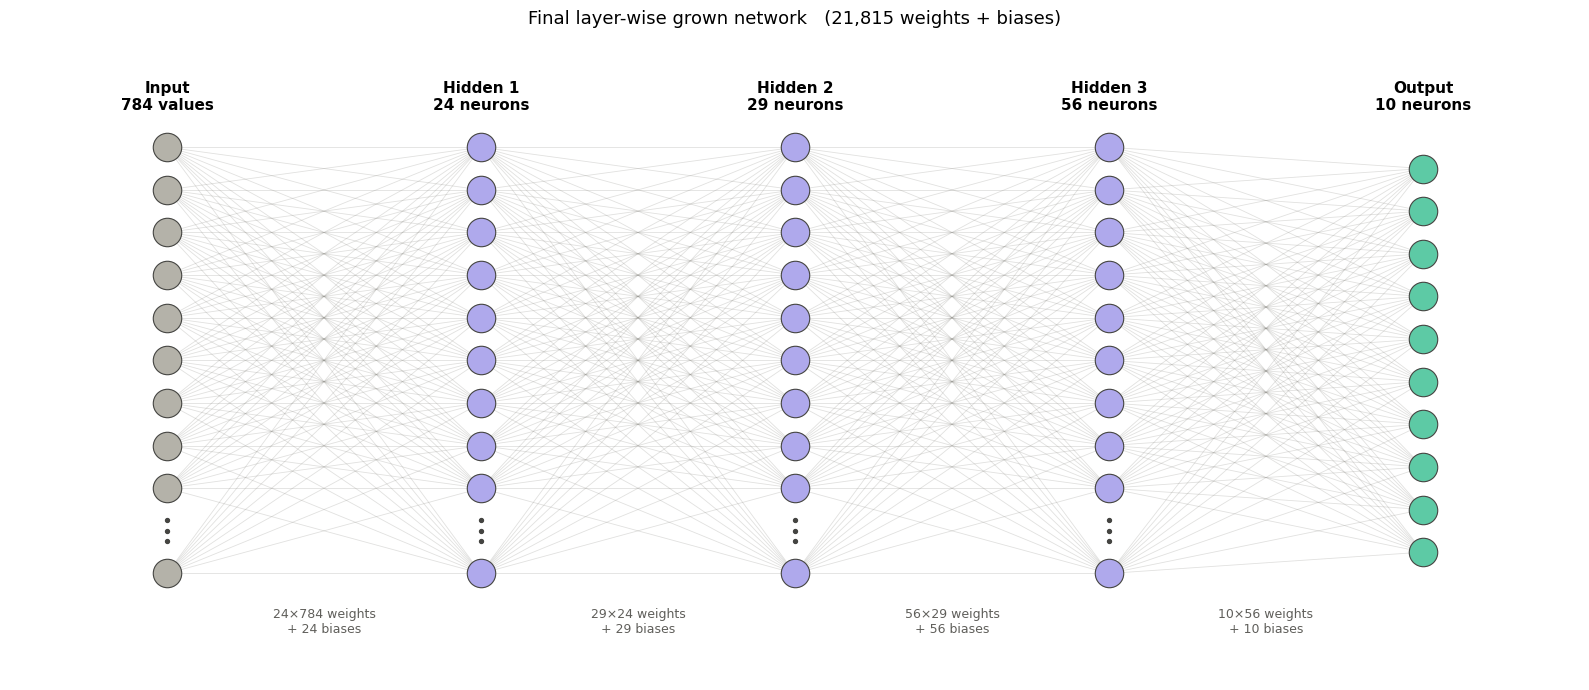

In [6]:
# ============================================================
# Section 4.2 - Experiment 4: layer-wise growth (scenario 4, deep)
#   * starts as 784 -> 1 -> 10
#   * every epoch: add one neuron to the newest hidden layer,
#     or, if the loss has plateaued, add a whole new hidden layer
#   * all learned weights are preserved at every growth step; new layers
#     start as identity layers (Net2DeeperNet), so the function is unchanged
#   * growth stops when training loss < 0.05; training continues to 100 epochs
#   * draws a diagram of the final network at the end
# ============================================================
# Requires Sections 3.1 and 4.1 (DeepMLP).

import matplotlib.pyplot as plt

EPOCHS_STEP4 = 100
TARGET_LOSS = 0.05           # stop all growth below this training loss
PLATEAU_DELTA = 0.005        # improvement smaller than this = layer has plateaued
MIN_EPOCHS_PER_LAYER = 3     # a layer trains at least this long before a new layer may be added
MAX_HIDDEN_LAYERS = 3


# ---------------- Growth operation 1: add one neuron ----------------
def add_neuron_to_last_layer(old_model):
    """Same as Step 2, but for the newest (last) hidden layer of a DeepMLP."""
    sizes = layer_sizes(old_model)
    h = sizes[-1]
    new_model = DeepMLP(sizes[:-1] + [h + 1]).to(device)

    with torch.no_grad():
        # earlier hidden layers: copied unchanged
        for i in range(len(sizes) - 1):
            new_model.hidden_layers[i].weight.copy_(old_model.hidden_layers[i].weight)
            new_model.hidden_layers[i].bias.copy_(old_model.hidden_layers[i].bias)
        # last hidden layer: old neurons' incoming weights (rows) + biases
        new_model.hidden_layers[-1].weight[:h, :] = old_model.hidden_layers[-1].weight
        new_model.hidden_layers[-1].bias[:h] = old_model.hidden_layers[-1].bias
        # output layer: old neurons' outgoing weights (columns) + all output biases
        new_model.output.weight[:, :h] = old_model.output.weight
        new_model.output.bias[:] = old_model.output.bias

    return new_model


# ---------------- Growth operation 2: add one layer ----------------
def add_identity_layer(old_model):
    """Insert a new hidden layer just before the output (Net2Net 'deeper' step).
       It has as many neurons as the layer before it and starts as the identity:
       neuron j simply copies neuron j of the previous layer. Because ReLU outputs
       are never negative, the network's predictions do not change at all."""
    sizes = layer_sizes(old_model)
    h = sizes[-1]
    new_model = DeepMLP(sizes + [h]).to(device)

    with torch.no_grad():
        for i in range(len(sizes)):                          # all existing hidden layers
            new_model.hidden_layers[i].weight.copy_(old_model.hidden_layers[i].weight)
            new_model.hidden_layers[i].bias.copy_(old_model.hidden_layers[i].bias)
        new_model.hidden_layers[-1].weight.copy_(torch.eye(h, device=device))   # identity
        new_model.hidden_layers[-1].bias.zero_()
        new_model.output.weight.copy_(old_model.output.weight)                  # output unchanged
        new_model.output.bias.copy_(old_model.output.bias)

    return new_model


# ---------------- Diagram of a network ----------------
def draw_network(hidden_sizes, title="Final neural network", save_path=None, max_shown=10):
    """Clean diagram: at most `max_shown` circles per layer (dots mark hidden ones),
       the real neuron count above each layer, the weight count below each connection."""
    sizes = [28 * 28] + list(hidden_sizes) + [10]
    names = ["Input"] + [f"Hidden {i + 1}" for i in range(len(hidden_sizes))] + ["Output"]
    colors = ["#B4B2A9"] + ["#AFA9EC"] * len(hidden_sizes) + ["#5DCAA5"]
    x_gap = 3.0
    half = (max_shown + 1) / 2

    fig, ax = plt.subplots(figsize=(3 + 2.6 * len(sizes), 7))
    layer_ys = []
    for li, n in enumerate(sizes):
        x = li * x_gap
        if n <= max_shown:                                   # draw every neuron
            ys = [(n - 1) / 2 - i for i in range(n)]
        else:                                                # draw first ones, a gap, the last one
            total = max_shown + 1
            slots = list(range(max_shown - 1)) + [max_shown]
            ys = [(total - 1) / 2 - s for s in slots]
            gap_y = (total - 1) / 2 - (max_shown - 1)
            ax.scatter([x] * 3, [gap_y - 0.25, gap_y, gap_y + 0.25], s=8, c="#444441", zorder=3)
        layer_ys.append(ys)
        ax.scatter([x] * len(ys), ys, s=420, c=colors[li], edgecolors="#444441", linewidths=0.8, zorder=3)
        label = f"{names[li]}\n{n} " + ("values" if li == 0 else "neurons")
        ax.text(x, half + 0.3, label, ha="center", va="bottom", fontsize=11, fontweight="bold")

    for li in range(len(sizes) - 1):                         # connections between shown neurons
        for y1 in layer_ys[li]:
            for y2 in layer_ys[li + 1]:
                ax.plot([li * x_gap, (li + 1) * x_gap], [y1, y2],
                        color="#888780", alpha=0.25, linewidth=0.6, zorder=1)
        ax.text((li + 0.5) * x_gap, -half - 0.3,
                f"{sizes[li + 1]}×{sizes[li]} weights\n+ {sizes[li + 1]} biases",
                ha="center", va="top", fontsize=9, color="#5F5E5A")

    total_params = sum(sizes[i] * sizes[i + 1] + sizes[i + 1] for i in range(len(sizes) - 1))
    ax.set_title(f"{title}   ({total_params:,} weights + biases)", fontsize=13, pad=12)
    ax.set_xlim(-1.5, (len(sizes) - 1) * x_gap + 1.5)
    ax.set_ylim(-half - 2.0, half + 2.0)
    ax.axis("off")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


# ---------------- The layer-wise growing training run ----------------
def run_layerwise(run_name, max_epochs=EPOCHS_STEP4, keep_training_after_target=True):
    run_dir = os.path.join(OUT_DIR, run_name)
    os.makedirs(run_dir, exist_ok=True)

    model = DeepMLP([1]).to(device)                 # 784 -> 1 -> 10
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    growing = True
    prev_loss = None
    epochs_in_layer = 0
    epoch_rows, neuron_rows = [], []
    start = time.time()

    for epoch in range(1, max_epochs + 1):
        # 1) train one epoch and record everything
        stats = train_one_epoch(model, optimizer, criterion)
        test_loss, test_acc = evaluate(model, criterion)
        log_epoch(model, epoch, stats, run_dir, neuron_rows)

        loss = stats["train_loss"]
        sizes = layer_sizes(model)
        epochs_in_layer += 1
        improvement = (prev_loss - loss) if prev_loss is not None else float("nan")

        # 2) decide what to do after this epoch
        target_reached = growing and loss < TARGET_LOSS
        action = "none"
        if growing and not target_reached and epoch < max_epochs:
            plateau = (prev_loss is not None and improvement < PLATEAU_DELTA
                       and epochs_in_layer >= MIN_EPOCHS_PER_LAYER)
            if plateau and len(sizes) < MAX_HIDDEN_LAYERS:
                action = "add_layer"
            else:
                action = "add_neuron"

        epoch_rows.append({
            "epoch": epoch,
            "hidden_sizes": str(sizes),
            "num_hidden_layers": len(sizes),
            "total_hidden_neurons": sum(sizes),
            "loss_improvement": improvement,
            "growth_action": action,
            "train_loss": loss,
            "train_acc": stats["train_acc"],
            "test_loss": test_loss,
            "test_acc": test_acc,
            "elapsed_sec": time.time() - start,
        })
        save_tables(run_dir, epoch_rows, neuron_rows)
        print(f"[{run_name}] Epoch {epoch:03d}/{max_epochs} | layers {str(sizes):<14} | "
              f"train loss {loss:.4f} acc {stats['train_acc']:.2f}% | "
              f"test acc {test_acc:.2f}% | next: {action}")

        # 3) target reached -> growth stops for good
        if target_reached:
            growing = False
            print(f"   Target loss < {TARGET_LOSS} reached at epoch {epoch} with hidden layers {sizes}. "
                  f"Growth stopped.")
            if not keep_training_after_target:
                break

        # 4) grow
        if action == "add_layer":
            model = add_identity_layer(model)
            epochs_in_layer = 0
            print(f"   New hidden layer added -> {layer_sizes(model)}")
        elif action == "add_neuron":
            model = add_neuron_to_last_layer(model)
        if action != "none":
            optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

        prev_loss = loss

    torch.save(model.state_dict(), os.path.join(run_dir, "final_model.pt"))
    final_sizes = layer_sizes(model)
    print(f"[{run_name}] done in {(time.time() - start) / 60:.1f} min, "
          f"final hidden layers {final_sizes} -> {run_dir}\n")

    draw_network(final_sizes, title="Final layer-wise grown network",
                 save_path=os.path.join(run_dir, "final_network.png"))
    return model


# Run scenario 4 with layer-wise growth
set_seed(SEED)
layerwise_model = run_layerwise("deep_growing_layerwise")

**Observation.** New layers were added at epochs 24 and 30, and the final architecture is 784 → 24 → 29 → 56 → 10, which reaches the target at epoch 58. Training accuracy continued to rise after both insertions, consistent with the identity layers preserving the learned function. However, the first layer stopped at 24 neurons after a single slow epoch (improvement 0.0045), and every later layer only sees those 24 values. The result, 96.14% test accuracy at epoch 100, is below the single-layer growing network. This **bottleneck** motivated Experiment 4b.

### 4.3 Experiment 4b: layer-wise growth with a smoothed plateau rule (extension)

A single epoch's improvement is a noisy signal. Experiment 4b changes only the plateau test of Experiment 4:

| | Experiment 4 | Experiment 4b |
|---|---|---|
| Plateau when | improvement in the last epoch $< 0.005$ | **average** improvement per epoch over the last 3 epochs $< 0.005$ |
| Minimum epochs per layer | 3 | 5 |

Since the first layer grows exactly as in Experiment 2 until the first layer is added, the effect could be predicted from Experiment 2's loss curve: over epochs 33–36 the loss fell from 0.0870 to 0.0731, an average of 0.0046 per epoch, so the first layer should stop at about 36 neurons.

[deep_growing_layerwise_v2] Epoch 001/100 | layers [1]            | train loss 2.1629 acc 12.12% | test acc 16.44% | next: add_neuron
[deep_growing_layerwise_v2] Epoch 002/100 | layers [2]            | train loss 1.5747 acc 37.38% | test acc 46.73% | next: add_neuron
[deep_growing_layerwise_v2] Epoch 003/100 | layers [3]            | train loss 1.0821 acc 64.55% | test acc 68.06% | next: add_neuron
[deep_growing_layerwise_v2] Epoch 004/100 | layers [4]            | train loss 0.9018 acc 70.47% | test acc 72.72% | next: add_neuron
[deep_growing_layerwise_v2] Epoch 005/100 | layers [5]            | train loss 0.6433 acc 82.53% | test acc 85.14% | next: add_neuron
[deep_growing_layerwise_v2] Epoch 006/100 | layers [6]            | train loss 0.4897 acc 86.92% | test acc 88.06% | next: add_neuron
[deep_growing_layerwise_v2] Epoch 007/100 | layers [7]            | train loss 0.4064 acc 88.93% | test acc 89.49% | next: add_neuron
[deep_growing_layerwise_v2] Epoch 008/100 | layers [8]        

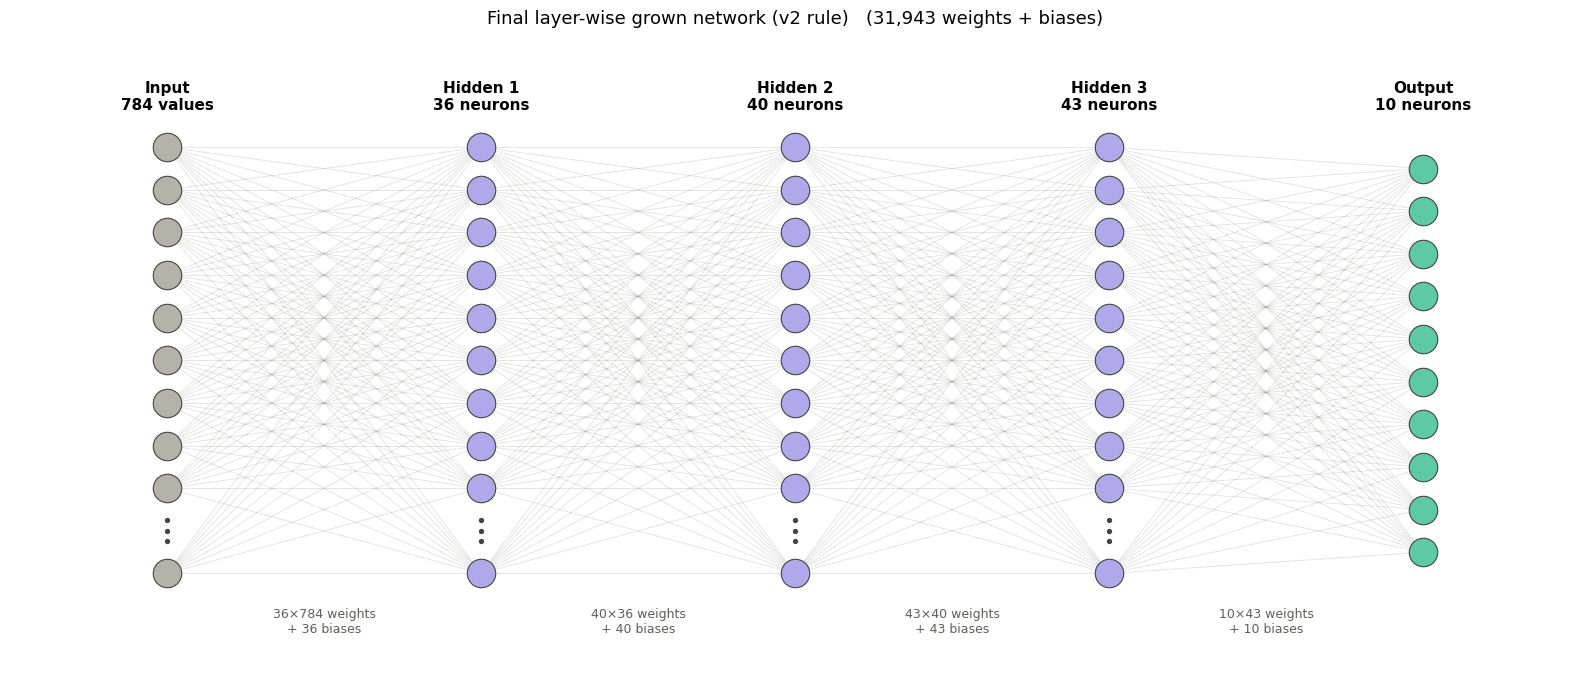

In [7]:
# ============================================================
# Section 4.3 - Experiment 4b: layer-wise growth, smoothed plateau rule
#   Same as Experiment 4, with one change: a layer counts as "plateaued" only when
#   the loss improved by less than 0.005 PER EPOCH on average over the last
#   3 epochs (not just the last 1), and a layer must train for at least 5 epochs.
#   This stops one noisy epoch from ending a layer too early.
# ============================================================
# Requires Sections 3.1, 4.1 and 4.2 (add_neuron_to_last_layer,
# add_identity_layer, draw_network).

PLATEAU_WINDOW = 3            # look at the average improvement over this many epochs
MIN_EPOCHS_PER_LAYER_V2 = 5   # a layer trains at least this long before a new one may be added


def run_layerwise_v2(run_name, max_epochs=EPOCHS_STEP4, keep_training_after_target=True):
    run_dir = os.path.join(OUT_DIR, run_name)
    os.makedirs(run_dir, exist_ok=True)

    model = DeepMLP([1]).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    growing = True
    losses = []                       # training loss of every epoch so far
    epochs_in_layer = 0
    epoch_rows, neuron_rows = [], []
    start = time.time()

    for epoch in range(1, max_epochs + 1):
        stats = train_one_epoch(model, optimizer, criterion)
        test_loss, test_acc = evaluate(model, criterion)
        log_epoch(model, epoch, stats, run_dir, neuron_rows)

        loss = stats["train_loss"]
        losses.append(loss)
        sizes = layer_sizes(model)
        epochs_in_layer += 1

        # Change from Experiment 4: average improvement per epoch over the last PLATEAU_WINDOW epochs
        if len(losses) > PLATEAU_WINDOW:
            improvement = (losses[-1 - PLATEAU_WINDOW] - loss) / PLATEAU_WINDOW
        else:
            improvement = float("nan")

        target_reached = growing and loss < TARGET_LOSS
        action = "none"
        if growing and not target_reached and epoch < max_epochs:
            plateau = (not np.isnan(improvement) and improvement < PLATEAU_DELTA
                       and epochs_in_layer >= MIN_EPOCHS_PER_LAYER_V2)
            if plateau and len(sizes) < MAX_HIDDEN_LAYERS:
                action = "add_layer"
            else:
                action = "add_neuron"

        epoch_rows.append({
            "epoch": epoch,
            "hidden_sizes": str(sizes),
            "num_hidden_layers": len(sizes),
            "total_hidden_neurons": sum(sizes),
            "loss_improvement": improvement,
            "growth_action": action,
            "train_loss": loss,
            "train_acc": stats["train_acc"],
            "test_loss": test_loss,
            "test_acc": test_acc,
            "elapsed_sec": time.time() - start,
        })
        save_tables(run_dir, epoch_rows, neuron_rows)
        print(f"[{run_name}] Epoch {epoch:03d}/{max_epochs} | layers {str(sizes):<14} | "
              f"train loss {loss:.4f} acc {stats['train_acc']:.2f}% | "
              f"test acc {test_acc:.2f}% | next: {action}")

        if target_reached:
            growing = False
            print(f"   Target loss < {TARGET_LOSS} reached at epoch {epoch} with hidden layers {sizes}. "
                  f"Growth stopped.")
            if not keep_training_after_target:
                break

        if action == "add_layer":
            model = add_identity_layer(model)
            epochs_in_layer = 0
            print(f"   New hidden layer added -> {layer_sizes(model)}")
        elif action == "add_neuron":
            model = add_neuron_to_last_layer(model)
        if action != "none":
            optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    torch.save(model.state_dict(), os.path.join(run_dir, "final_model.pt"))
    final_sizes = layer_sizes(model)
    print(f"[{run_name}] done in {(time.time() - start) / 60:.1f} min, "
          f"final hidden layers {final_sizes} -> {run_dir}\n")

    draw_network(final_sizes, title="Final layer-wise grown network (v2 rule)",
                 save_path=os.path.join(run_dir, "final_network.png"))
    return model


set_seed(SEED)
layerwise_model_v2 = run_layerwise_v2("deep_growing_layerwise_v2")

**Observation.** As predicted, the first layer grew to 36 neurons. Layers were added at epochs 36 and 41, the target was reached at epoch 45, and the final architecture is 784 → 36 → 40 → 43 → 10. Test accuracy at epoch 100 improved from 96.14% to 96.99% (best 97.10%), which confirms that the bottleneck in Experiment 4 was caused by the plateau rule.

## 5. Analysis of the recorded data

This section reads only the files written in Sections 3 and 4, so it can be re-run without retraining. It is divided into eight parts: a data-integrity check, a summary table, learning curves, growth trajectories, three levels of weight and gradient analysis, and an export of all results.

### 5.1 Data integrity

Every epoch writes exactly one `.npz` file, so the number of `.npz` files is an independent record of how many epochs a run completed. The check below compares it with the number of rows in each run's CSV files. A mismatch would mean that a run was restarted or interrupted and part of its tables was overwritten.

In [8]:
# ============================================================
# Section 5 - Analysis of all logged runs
#   Self-contained: reads only the files in OUT_DIR, so it can be
#   re-run without retraining.
# ============================================================

import os
import ast
import glob
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

OUT_DIR = "/kaggle/working/experiment_logs"
PLOT_DIR = os.path.join(OUT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)


def save_and_show(fig, filename):
    fig.savefig(os.path.join(PLOT_DIR, filename), dpi=150, bbox_inches="tight")
    plt.show()


# ------------------------------------------------------------
# 5.1 Data integrity: load every run and check that nothing is missing
# ------------------------------------------------------------
def load_runs(out_dir=OUT_DIR):
    runs = {}
    for name in sorted(os.listdir(out_dir)):
        run_dir = os.path.join(out_dir, name)
        summary_file = os.path.join(run_dir, "epoch_summary.csv")
        if not os.path.isfile(summary_file):
            continue                                     # skips the plots folder etc.
        epochs = pd.read_csv(summary_file)
        epochs["sizes"] = epochs["hidden_sizes"].apply(ast.literal_eval)   # "[24, 29]" -> [24, 29]
        neurons = pd.read_csv(os.path.join(run_dir, "neuron_stats.csv"))
        runs[name] = {"epochs": epochs, "neurons": neurons, "dir": run_dir}
    return runs


runs = load_runs()
print("Runs found:", list(runs), "\n")

problems = []
for name, r in runs.items():
    logged = set(r["epochs"]["epoch"])
    n_npz = len(glob.glob(os.path.join(r["dir"], "epoch_*.npz")))
    expected = max(max(logged), n_npz)                  # every epoch writes one .npz file
    missing = sorted(set(range(1, expected + 1)) - logged)
    status = "OK" if not missing else f"PROBLEM: {len(missing)} epochs missing from the CSV files"
    if missing:
        problems.append(name)
    print(f"{name:28s} epochs in CSV: {len(logged):3d} | .npz files: {n_npz:3d} | {status}")
if problems:
    print("\nWARNING - re-run these experiments before using the results:", problems)
else:
    print("\nAll runs are complete.")


def pretty_layer(layer):
    """'hidden' -> 'Hidden layer 1', 'hidden_layers.1' -> 'Hidden layer 2'."""
    if layer == "hidden":
        return "Hidden layer 1"
    if layer.startswith("hidden_layers."):
        return f"Hidden layer {int(layer.split('.')[1]) + 1}"
    return layer


def n_params(hidden_sizes):
    sizes = [28 * 28] + list(hidden_sizes) + [10]
    return sum(sizes[i] * sizes[i + 1] + sizes[i + 1] for i in range(len(sizes) - 1))


Runs found: ['deep_fixed_100x100', 'deep_fixed_20x20', 'deep_fixed_44x44', 'deep_growing_layerwise', 'deep_growing_layerwise_v2', 'mlp_fixed_100', 'mlp_fixed_20', 'mlp_fixed_44', 'mlp_growing_from_1', 'mlp_growing_from_1_revive'] 

deep_fixed_100x100           epochs in CSV:  50 | .npz files:  50 | OK
deep_fixed_20x20             epochs in CSV:  50 | .npz files:  50 | OK
deep_fixed_44x44             epochs in CSV:  50 | .npz files:  50 | OK
deep_growing_layerwise       epochs in CSV: 100 | .npz files: 100 | OK
deep_growing_layerwise_v2    epochs in CSV: 100 | .npz files: 100 | OK
mlp_fixed_100                epochs in CSV:  50 | .npz files:  50 | OK
mlp_fixed_20                 epochs in CSV:  50 | .npz files:  50 | OK
mlp_fixed_44                 epochs in CSV:  50 | .npz files:  50 | OK
mlp_growing_from_1           epochs in CSV:  50 | .npz files:  50 | OK
mlp_growing_from_1_revive    epochs in CSV:  50 | .npz files:  50 | OK

All runs are complete.


All ten runs are complete: for every run the CSV files contain one row per epoch, matching the number of `.npz` snapshots.

### 5.2 Summary table

One row per run; the table is also saved as `summary_table.csv`. The columns used in the discussion are:

| Column | Meaning |
|---|---|
| `first_epoch_train_loss<0.05` | first epoch at which the training loss fell below the growth target |
| `test_acc_at_epoch_50` | test accuracy at epoch 50, the common comparison point for all runs |
| `best_test_acc`, `best_epoch` | highest test accuracy observed during training. It is selected with the test set and is therefore optimistic; it is reported for completeness only |
| `train_minus_test_acc` | training minus test accuracy at the final epoch, a simple measure of overfitting |
| `dead_hidden_neurons` | hidden neurons with an active rate below 1% at the final epoch |

The *final* columns refer to epoch 50, except for Experiments 4 and 4b, which end at epoch 100.

In [9]:
# ------------------------------------------------------------
# 5.2 Summary table
# ------------------------------------------------------------
DEAD_THRESHOLD = 0.01     # a neuron active on < 1% of images is counted as "dead"


def run_order(name):
    """Fixed runs first, largest to smallest, then the growing runs."""
    numbers = "".join(ch if ch.isdigit() else " " for ch in name).split()
    first_number = int(numbers[0]) if numbers else 0
    growing = "growing" in name
    return (growing, 0 if growing else -first_number, name)


def summarise(name, r):
    ep = r["epochs"]
    ns = r["neurons"]
    final_hidden = ns[(ns["epoch"] == ns["epoch"].max()) & (ns["layer"] != "output")]
    n_dead = int((final_hidden["active_rate"] < DEAD_THRESHOLD).sum())
    last = ep.iloc[-1]
    best = ep.loc[ep["test_acc"].idxmax()]
    at_50 = ep[ep["epoch"] == 50]
    below_target = ep[ep["train_loss"] < 0.05]
    return {
        "run": name,
        "type": "growing" if "growing" in name else "fixed",
        "final_hidden_sizes": str(last["sizes"]),
        "parameters": n_params(last["sizes"]),
        "epochs": int(last["epoch"]),
        "first_epoch_train_loss<0.05": int(below_target["epoch"].iloc[0]) if len(below_target) else None,
        "test_acc_at_epoch_50": round(at_50["test_acc"].iloc[0], 2) if len(at_50) else None,
        "best_test_acc": round(best["test_acc"], 2),
        "best_epoch": int(best["epoch"]),
        "final_train_acc": round(last["train_acc"], 2),
        "final_test_acc": round(last["test_acc"], 2),
        "final_test_loss": round(last["test_loss"], 4),
        "train_minus_test_acc": round(last["train_acc"] - last["test_acc"], 2),   # overfitting gap
        "dead_hidden_neurons": f"{n_dead} of {len(final_hidden)}",
        "training_time_min": round(last["elapsed_sec"] / 60, 1),
    }


summary = pd.DataFrame([summarise(n, runs[n]) for n in sorted(runs, key=lambda n: (n.startswith("deep"), run_order(n)))])
summary.to_csv(os.path.join(OUT_DIR, "summary_table.csv"), index=False)
display(summary)

single_layer_runs = sorted([n for n in runs if n.startswith("mlp_")], key=run_order)
deep_runs = sorted([n for n in runs if n.startswith("deep_")], key=run_order)
growing_runs = sorted([n for n in runs if "growing" in n], key=run_order)


,run,type,final_hidden_sizes,parameters,epochs,first_epoch_train_loss<0.05,test_acc_at_epoch_50,best_test_acc,best_epoch,final_train_acc,final_test_acc,final_test_loss,train_minus_test_acc,dead_hidden_neurons,training_time_min
0,mlp_fixed_100,fixed,[100],79510,50,6,98.13,98.22,35,100.00,98.13,0.1163,1.87,4 of 100,7.4
1,mlp_fixed_44,fixed,[44],34990,50,12,97.06,97.51,13,99.77,97.06,0.1762,2.71,1 of 44,7.2
2,mlp_fixed_20,fixed,[20],15910,50,49,95.79,96.25,25,98.36,95.79,0.1756,2.57,0 of 20,7.2
3,mlp_growing_from_1,growing,[44],34990,50,44,97.01,97.19,48,98.96,97.01,0.1251,1.95,11 of 44,7.3
4,mlp_growing_from_1_revive,growing,[38],30220,50,38,97.07,97.10,49,99.27,97.07,0.1270,2.20,1 of 38,7.3
5,deep_fixed_100x100,fixed,"[100, 100]",89610,50,6,97.82,98.06,37,99.80,97.82,0.1739,1.98,5 of 200,7.4
6,deep_fixed_44x44,fixed,"[44, 44]",36970,50,12,97.30,97.48,41,99.61,97.30,0.1890,2.31,3 of 88,7.3
7,deep_fixed_20x20,fixed,"[20, 20]",16330,50,48,95.96,96.15,45,98.48,95.96,0.1762,2.52,1 of 40,7.2
8,deep_growing_layerwise,growing,"[24, 29, 56]",21815,100,58,96.29,96.48,49,99.15,96.14,0.2478,3.01,20 of 109,14.7
9,deep_growing_layerwise_v2,growing,"[36, 40, 43]",31943,100,45,96.45,97.10,90,99.68,96.99,0.2442,2.70,24 of 119,14.7


### 5.3 Learning curves

Training loss, test loss, training accuracy and test accuracy for every run. Growing runs are dashed. Both loss panels use a logarithmic scale, and the dotted line marks the growth target of 0.05. The accuracy panels are restricted to 90–100% so that the differences between the final networks are visible.

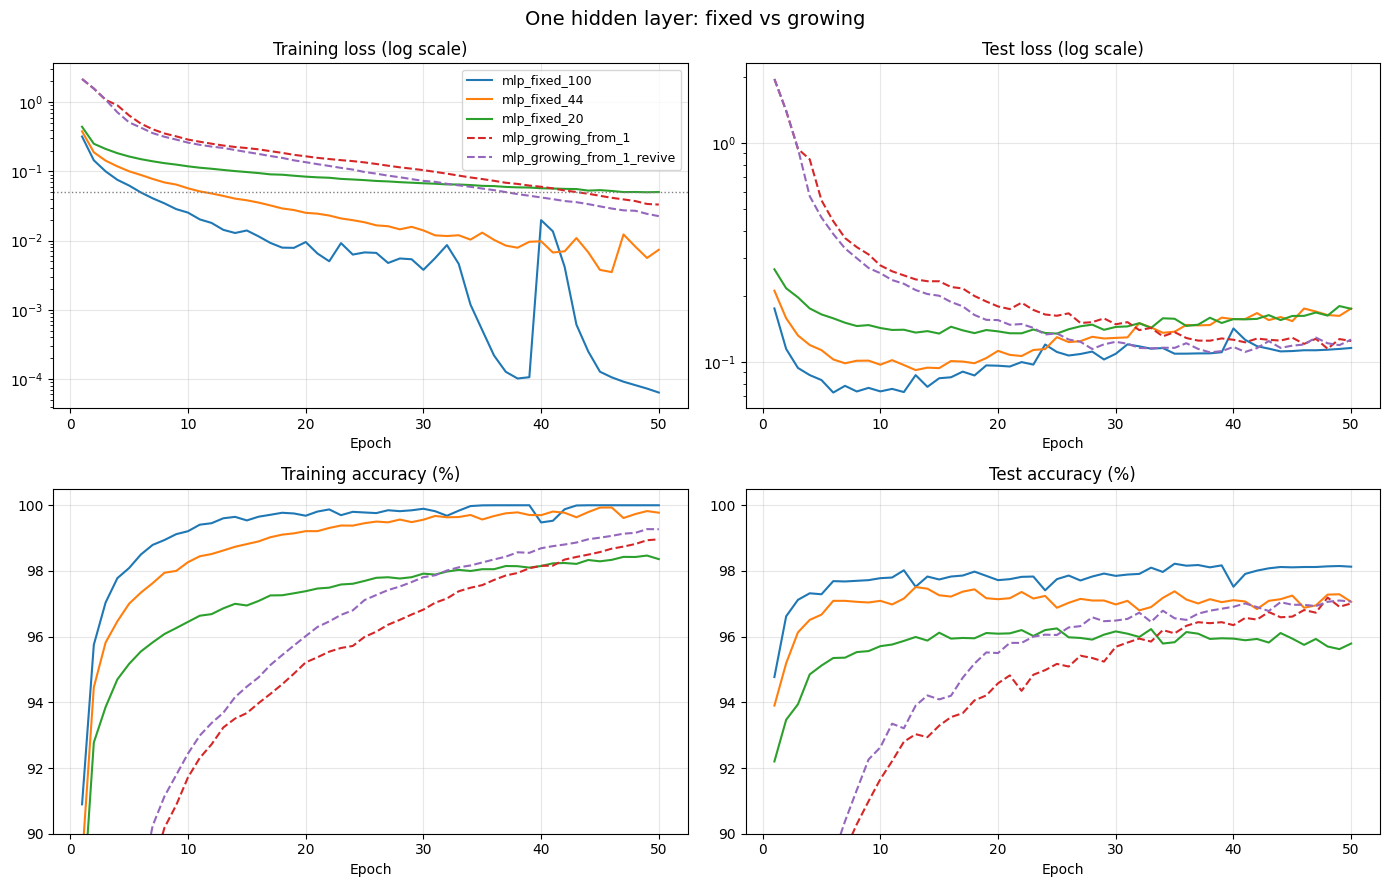

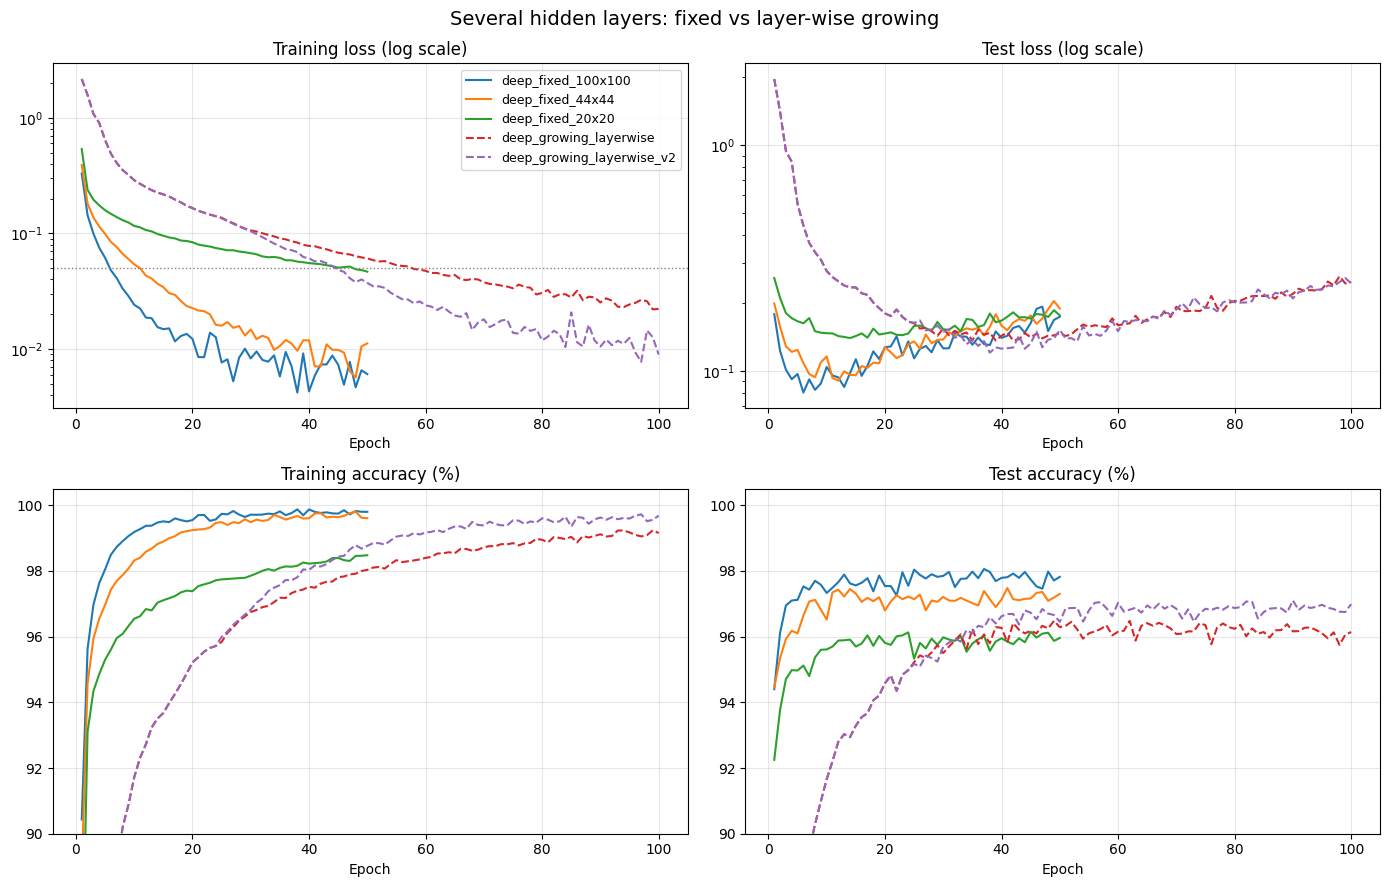

In [10]:
# ------------------------------------------------------------
# 5.3 Learning curves: loss and accuracy of all runs
# ------------------------------------------------------------
def plot_comparison(run_names, title, filename):
    panels = [("train_loss", "Training loss (log scale)"),
              ("test_loss", "Test loss (log scale)"),
              ("train_acc", "Training accuracy (%)"),
              ("test_acc", "Test accuracy (%)")]
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for ax, (column, label) in zip(axes.flat, panels):
        for name in run_names:
            ep = runs[name]["epochs"]
            style = "--" if "growing" in name else "-"          # growing runs = dashed
            ax.plot(ep["epoch"], ep[column], style, linewidth=1.5, label=name)
        ax.set_title(label)
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        if column.endswith("loss"):
            ax.set_yscale("log")
        if column == "train_loss":
            ax.axhline(0.05, color="gray", linestyle=":", linewidth=1)   # growth target
        if column.endswith("acc"):
            ax.set_ylim(90, 100.5)                               # zoom in on the interesting part
    axes[0, 0].legend(fontsize=9)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    save_and_show(fig, filename)


plot_comparison(single_layer_runs, "One hidden layer: fixed vs growing", "compare_single_layer.png")
plot_comparison(deep_runs, "Several hidden layers: fixed vs layer-wise growing", "compare_deep.png")


**Discussion.**

- **The fixed networks overfit.** Their test loss is lowest early (epochs 6, 13 and 25 for 100, 44 and 20 neurons) and then rises to 0.116, 0.176 and 0.176 at epoch 50, while their training loss keeps falling. The 100-neuron network drives its training loss to about $10^{-4}$, i.e. it memorises the training set. The brief spike at epoch 40 is a known instability of Adam when the loss is close to zero.
- **The growing networks are still improving at epoch 50.** Their test loss is still falling (0.125 and 0.127), and their final test loss is lower than that of the fixed 44- and 20-neuron networks.
- **Revival speeds up growth.** The curve of Experiment 2b lies above that of Experiment 2 from about epoch 10 onwards, so it reaches the target six epochs earlier.
- **Deep networks.** The same pattern holds. After growth stops, the layer-wise networks train for another 42–55 epochs and their test loss rises to about 0.25, the same overfitting seen in the fixed networks.

### 5.4 Growth trajectories

For each growing run, the coloured bands show the number of neurons in each hidden layer at every epoch, and the black line the training loss (logarithmic scale). The red dashed line marks the epoch at which the network reached its final size, and purple dotted lines mark the insertion of a new layer.

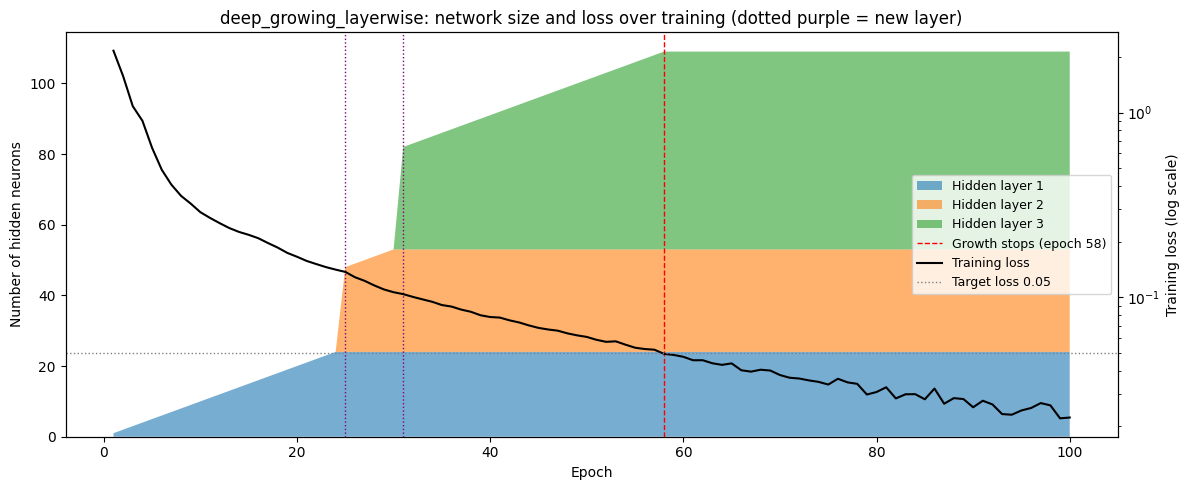

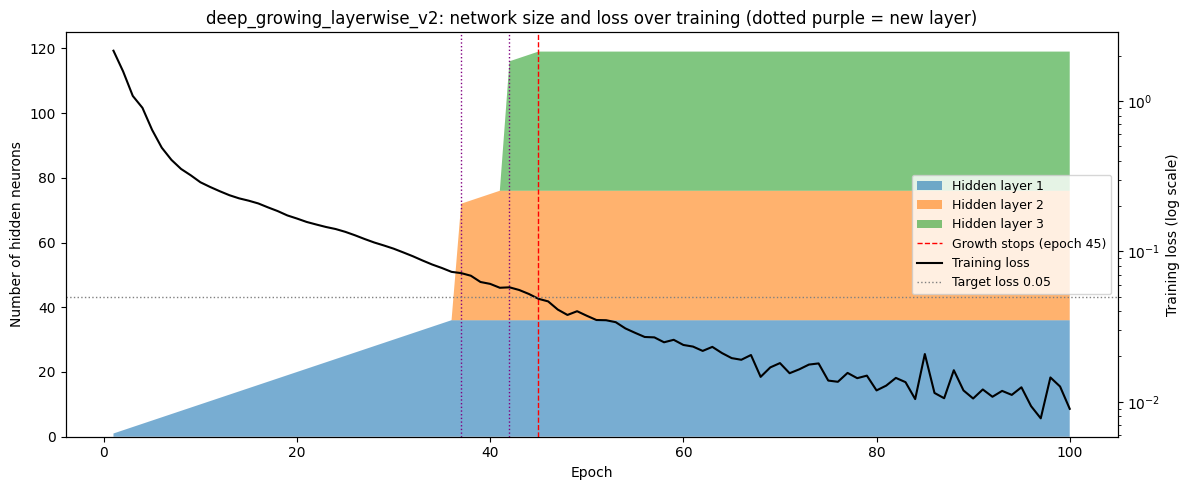

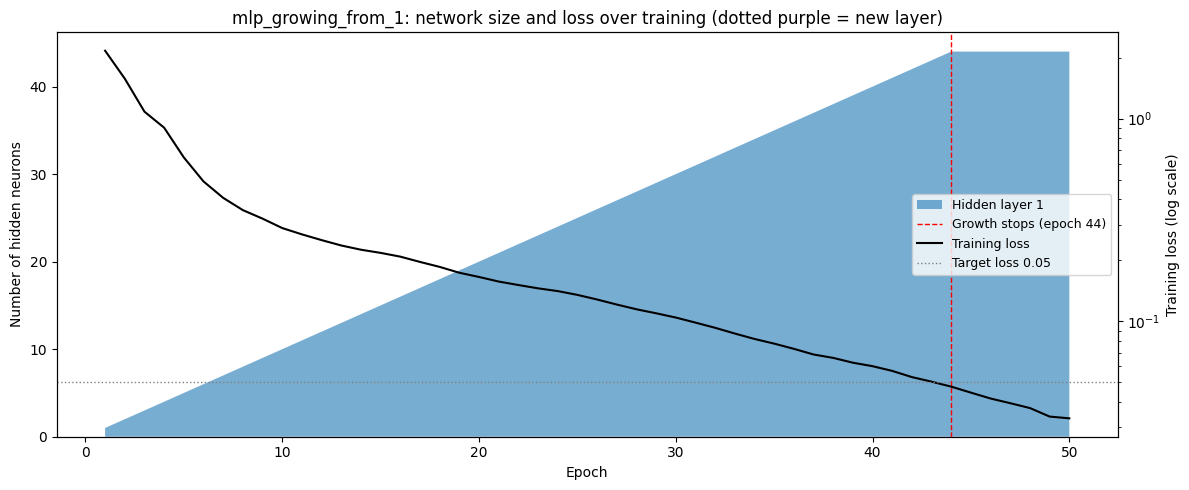

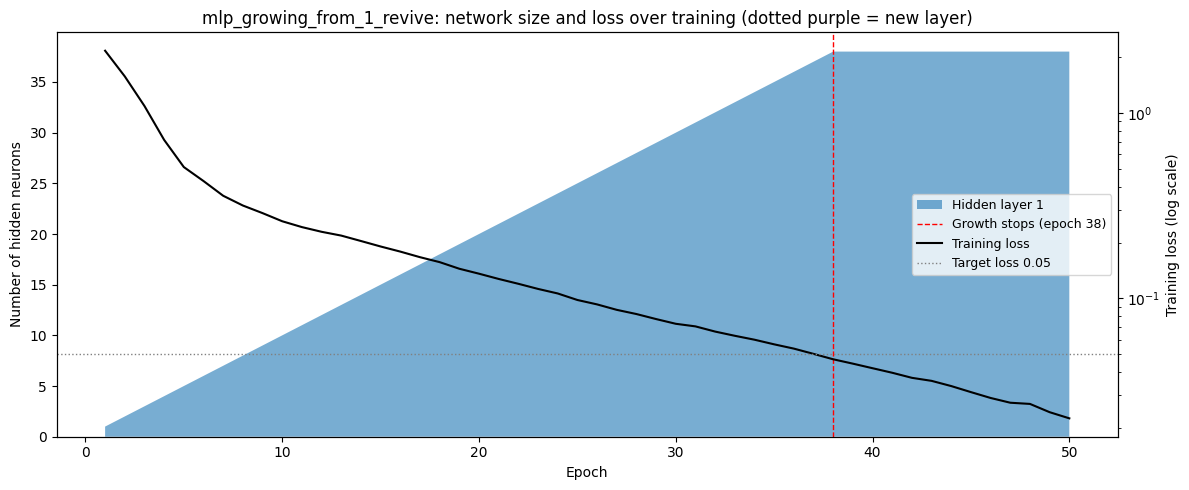

In [11]:
# ------------------------------------------------------------
# 5.4 Growth trajectories of the growing runs
# ------------------------------------------------------------
def plot_growth(name):
    ep = runs[name]["epochs"]
    sizes = ep["sizes"].tolist()
    n_layers = max(len(s) for s in sizes)
    per_layer = np.array([s + [0] * (n_layers - len(s)) for s in sizes]).T   # [layer, epoch]
    totals = per_layer.sum(axis=0)
    stop_epoch = int(ep["epoch"].iloc[np.argmax(totals == totals[-1])])     # first epoch at final size

    fig, ax1 = plt.subplots(figsize=(12, 5))
    ax1.stackplot(ep["epoch"], per_layer, alpha=0.6,
                  labels=[f"Hidden layer {i + 1}" for i in range(n_layers)])
    ax1.axvline(stop_epoch, color="red", linestyle="--", linewidth=1,
                label=f"Growth stops (epoch {stop_epoch})")
    for i in range(1, len(sizes)):                                        # mark new layers
        if len(sizes[i]) > len(sizes[i - 1]):
            ax1.axvline(ep["epoch"].iloc[i], color="purple", linestyle=":", linewidth=1)
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Number of hidden neurons")

    ax2 = ax1.twinx()
    ax2.plot(ep["epoch"], ep["train_loss"], color="black", linewidth=1.5, label="Training loss")
    ax2.axhline(0.05, color="gray", linestyle=":", linewidth=1, label="Target loss 0.05")
    ax2.set_yscale("log")
    ax2.set_ylabel("Training loss (log scale)")

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right", fontsize=9)
    ax1.set_title(f"{name}: network size and loss over training (dotted purple = new layer)")
    plt.tight_layout()
    save_and_show(fig, f"growth_{name}.png")


for name in growing_runs:
    plot_growth(name)


**Discussion.** Single-layer growth is linear until the loss crosses 0.05: 44 neurons in Experiment 2 and 38 in Experiment 2b. The layer-wise runs show the effect of the plateau rule directly: in Experiment 4 the first band stops at 24 neurons, while in Experiment 4b it continues to 36. Each identity layer starts as wide as the layer below it, which appears as a step in the band.

### 5.5 Per-neuron dynamics

The finest level of the recorded data. Each heatmap row is one hidden neuron and each column one epoch. The three panels show the L2 norm of the neuron's incoming weights, the L2 norm of its epoch-averaged gradient ($\log_{10}$), and its active rate. In growing runs, white cells are neurons that did not exist yet, so growth appears as a triangle.

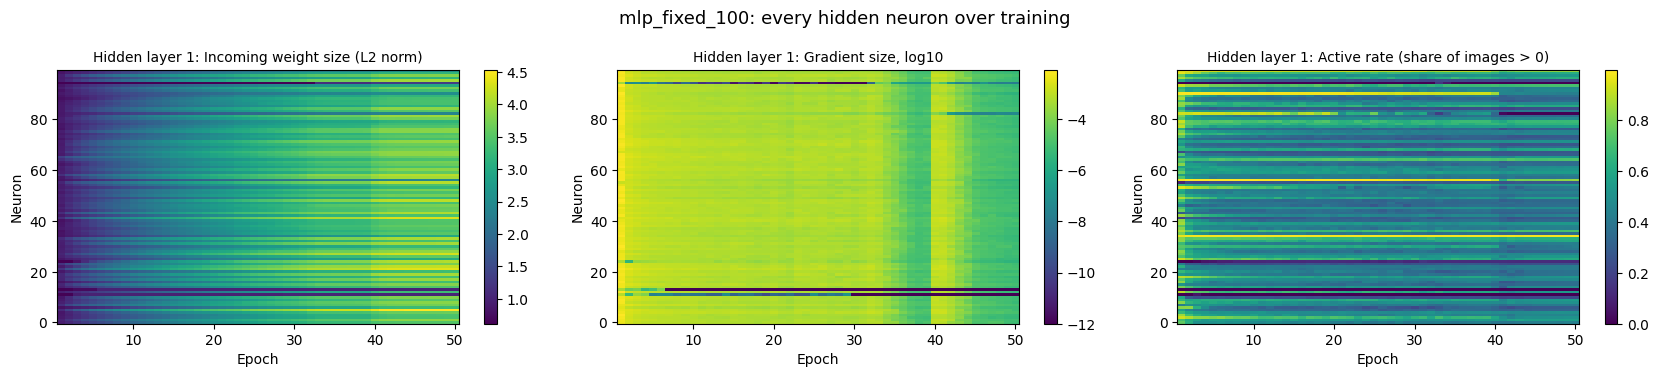

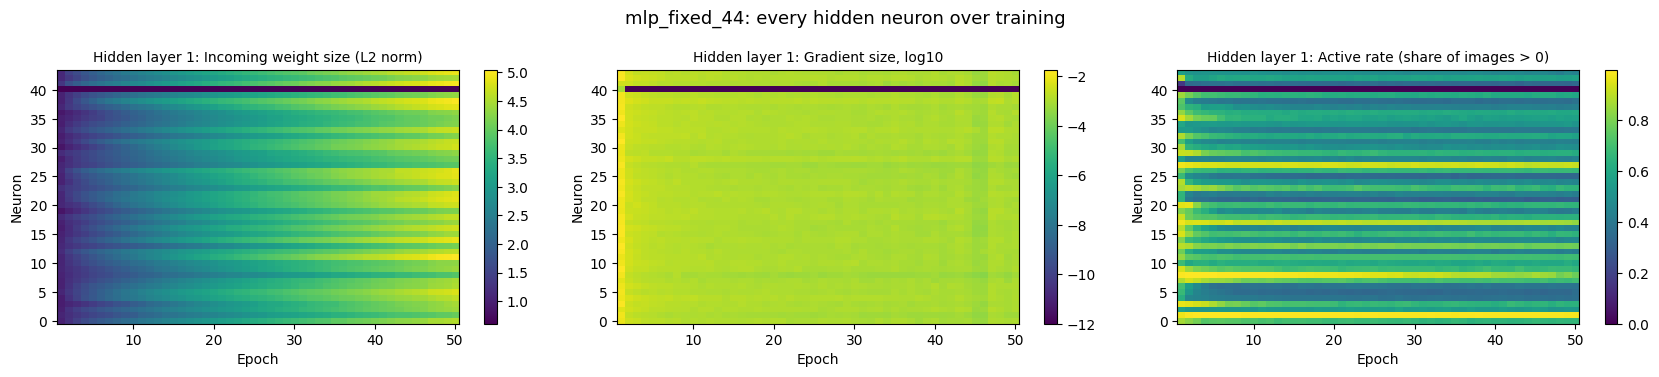

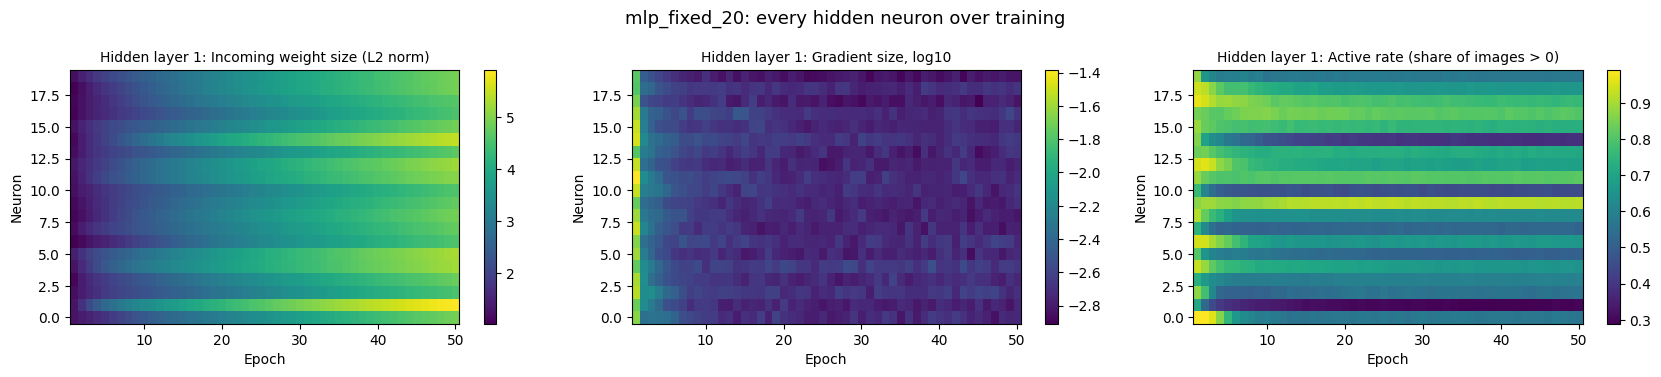

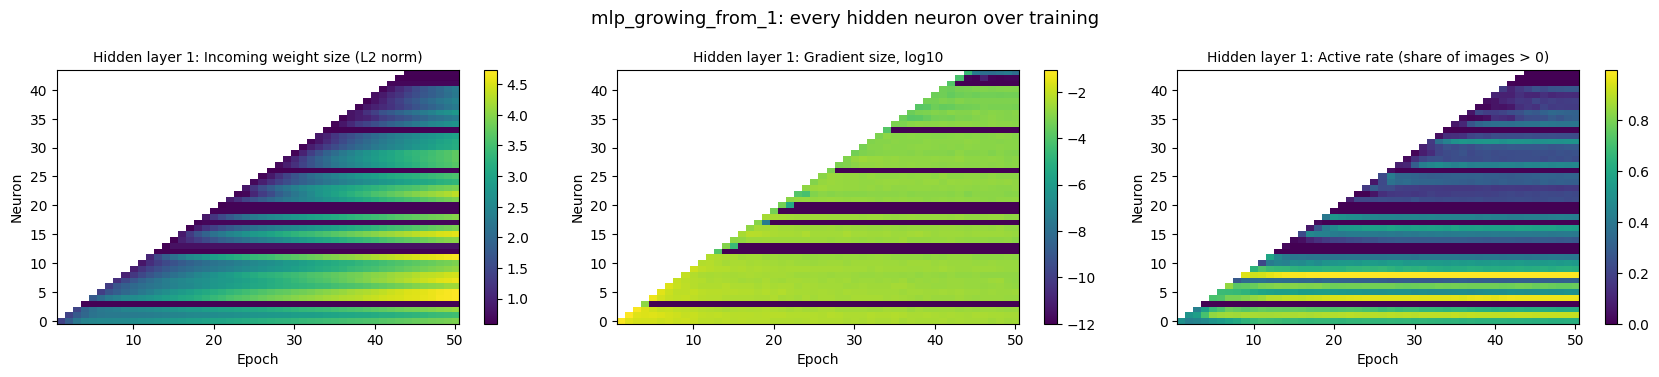

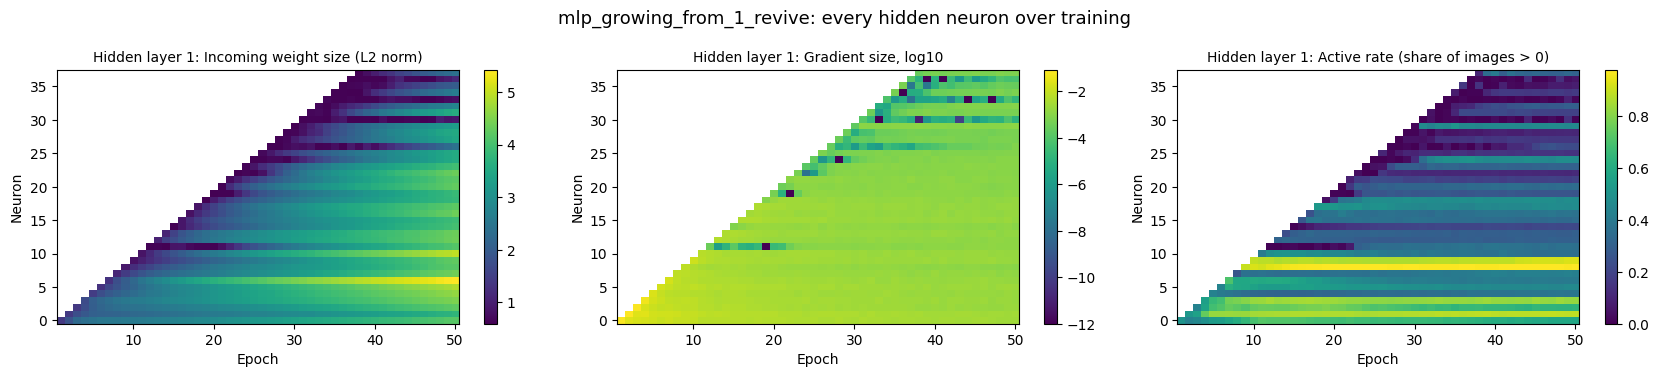

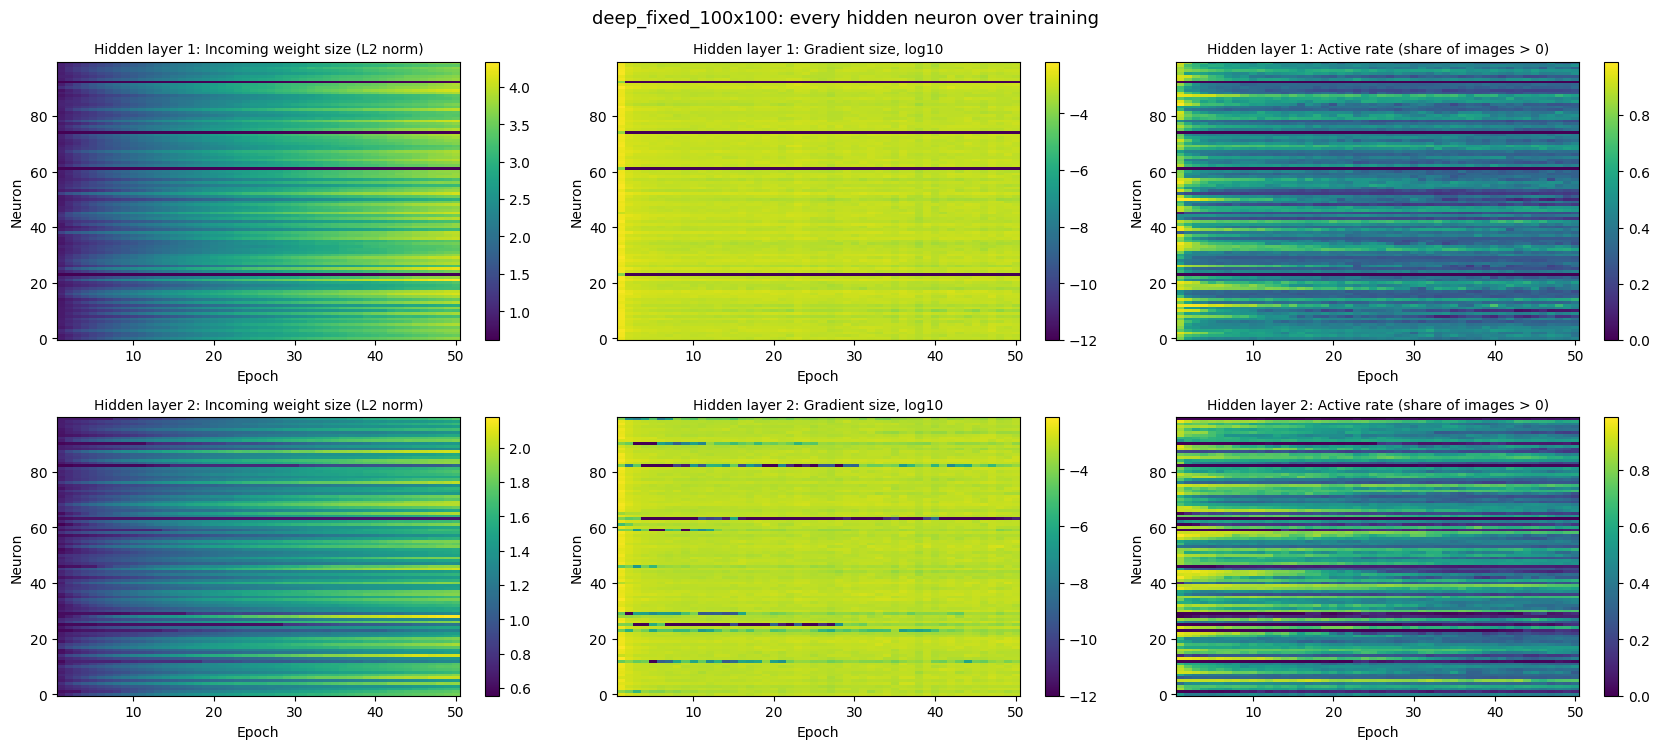

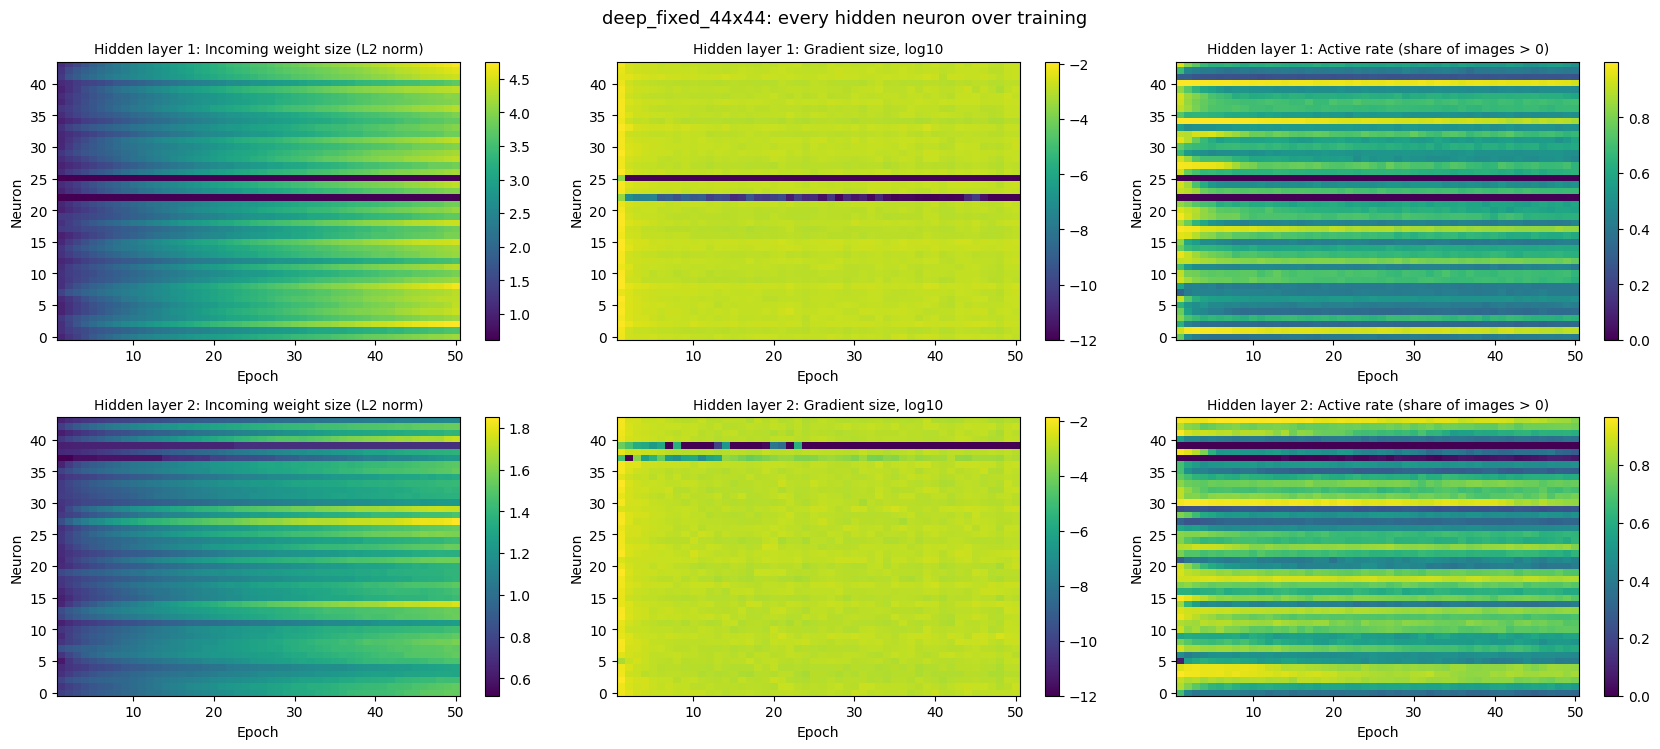

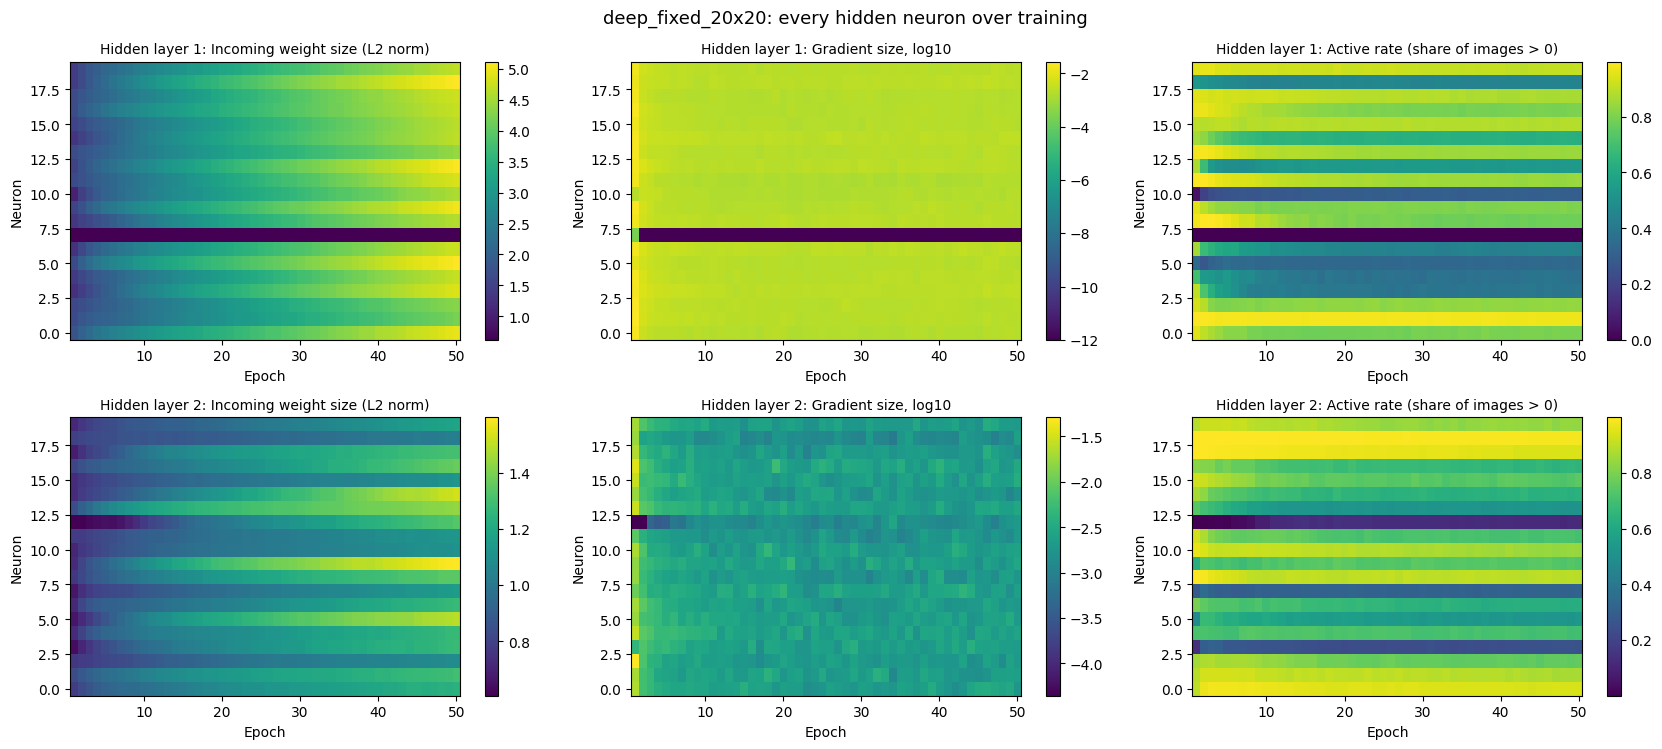

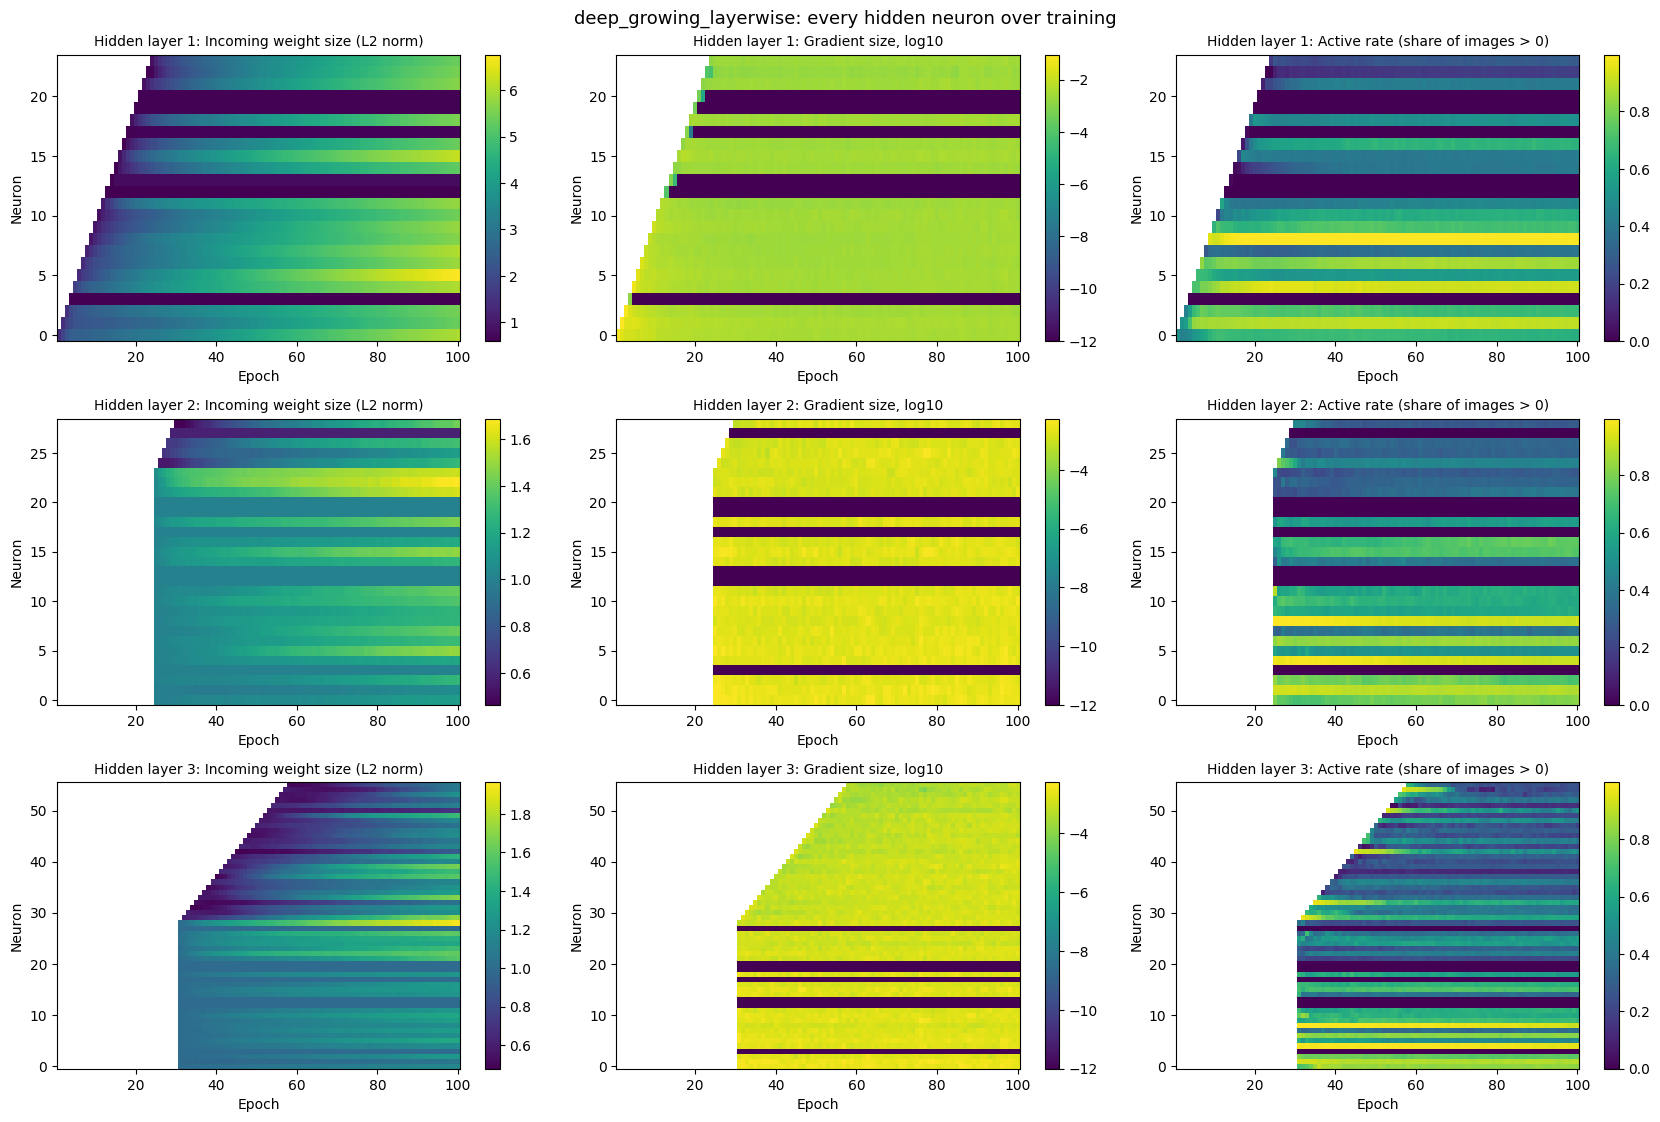

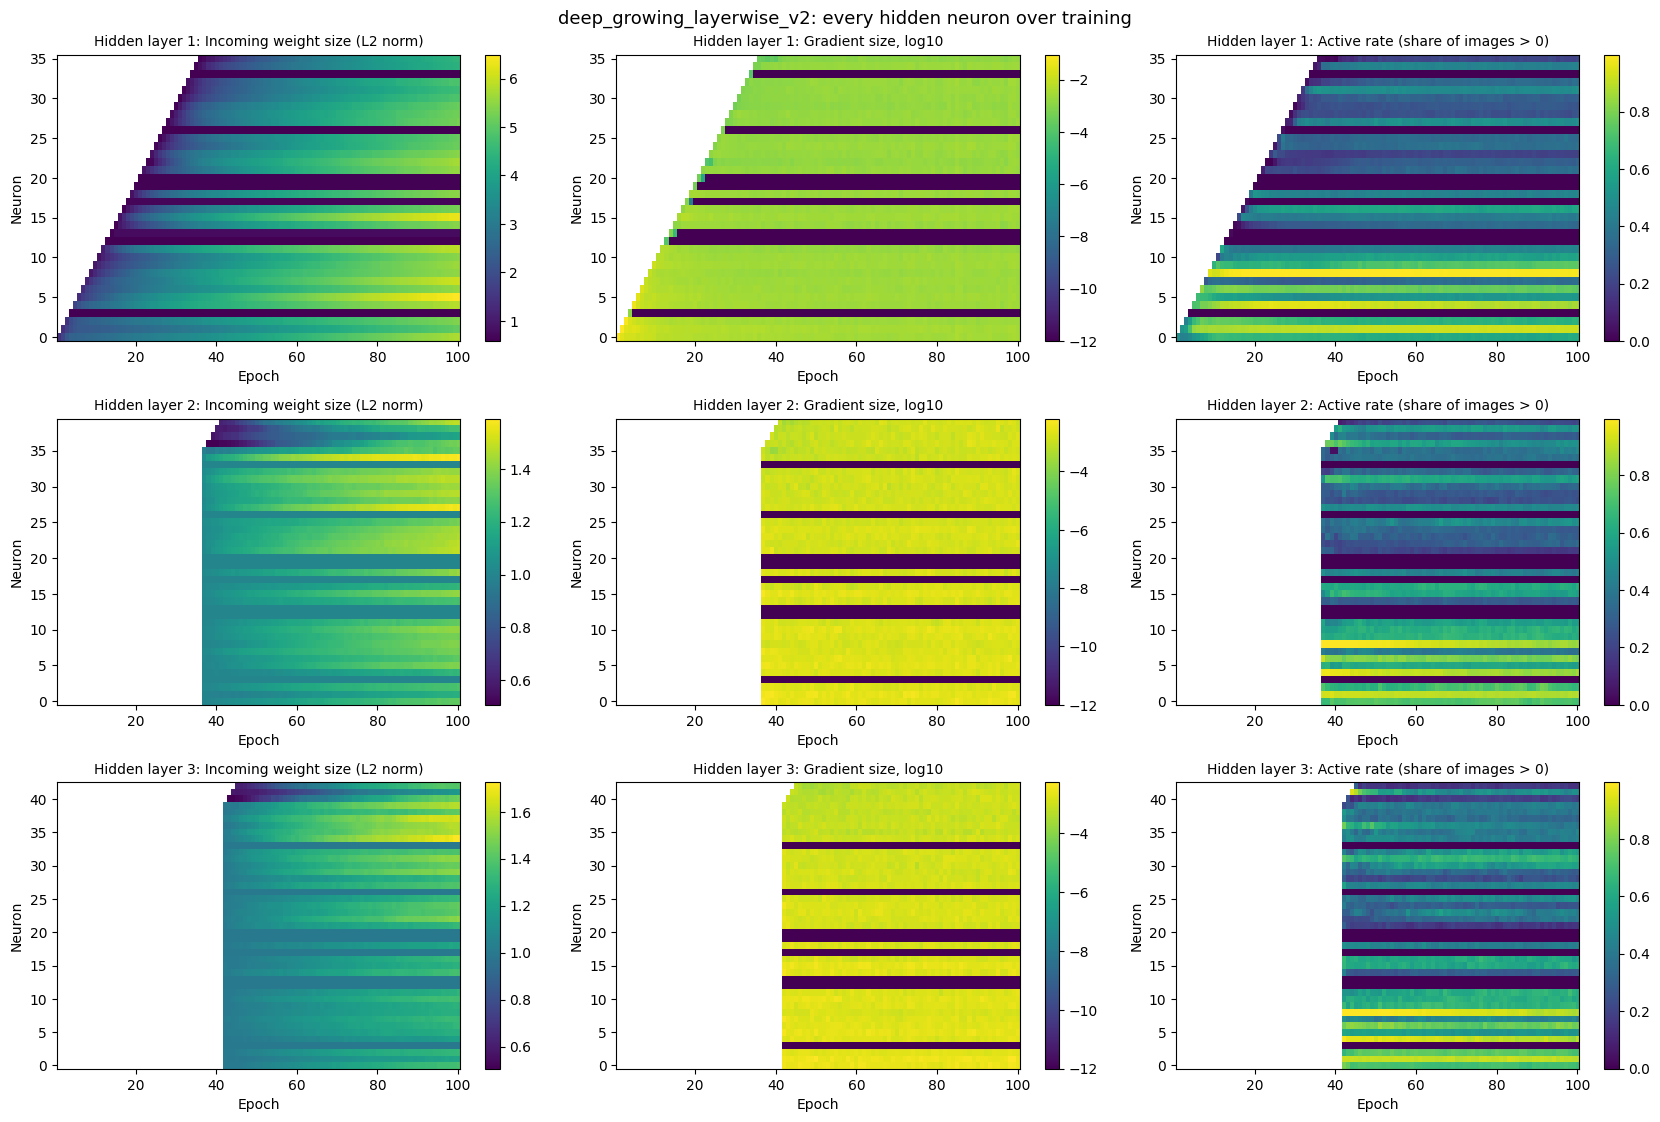

In [12]:
# ------------------------------------------------------------
# 5.5 Per-neuron dynamics: one row per neuron, one column per epoch
# ------------------------------------------------------------
HEATMAP_METRICS = [("weight_l2_norm", "Incoming weight size (L2 norm)"),
                   ("weight_grad_l2_norm", "Gradient size, log10"),
                   ("active_rate", "Active rate (share of images > 0)")]


def plot_neuron_heatmaps(name):
    ns = runs[name]["neurons"]
    last_epoch = int(ns["epoch"].max())
    hidden_layers = [layer for layer in ns["layer"].unique() if layer != "output"]

    fig, axes = plt.subplots(len(hidden_layers), len(HEATMAP_METRICS),
                             figsize=(17, 3.8 * len(hidden_layers)), squeeze=False)
    for i, layer in enumerate(hidden_layers):
        sub = ns[ns["layer"] == layer]
        for j, (metric, label) in enumerate(HEATMAP_METRICS):
            grid = sub.pivot(index="neuron", columns="epoch", values=metric)
            grid = grid.reindex(columns=range(1, last_epoch + 1))      # same x-axis everywhere
            values = grid.values.astype(float)
            if metric == "weight_grad_l2_norm":
                values = np.log10(values + 1e-12)
            cmap = plt.get_cmap("viridis").copy()
            cmap.set_bad("white")                                      # white = neuron not born yet
            im = axes[i, j].imshow(np.ma.masked_invalid(values), aspect="auto", origin="lower",
                                   cmap=cmap, interpolation="nearest",
                                   extent=[0.5, last_epoch + 0.5, -0.5, values.shape[0] - 0.5])
            fig.colorbar(im, ax=axes[i, j])
            axes[i, j].set_title(f"{pretty_layer(layer)}: {label}", fontsize=10)
            axes[i, j].set_xlabel("Epoch")
            axes[i, j].set_ylabel("Neuron")
    fig.suptitle(f"{name}: every hidden neuron over training", fontsize=13)
    plt.tight_layout()
    save_and_show(fig, f"neurons_{name}.png")


for name in single_layer_runs + deep_runs:
    plot_neuron_heatmaps(name)


**Discussion.**

- **New neurons learn fastest.** Each new neuron starts with the largest gradient in its layer, which shrinks as the neuron settles; at the same time its weight norm grows.
- **Dead neurons in Experiment 2.** Continuous dark horizontal lines appear in all three panels: zero activity, a gradient of (numerically) zero, and a weight norm that never changes. These are the 11 dead neurons. Once dead, a neuron in the first hidden layer cannot recover, because its inputs, the pixels, never change.
- **Experiment 2b.** The dark lines are short: neurons still die, but they are revived after one epoch.
- **Inherited dead neurons in Experiments 4 and 4b.** The *same neuron indices* are dark in every layer. In Experiment 4b neurons 3, 12, 13, 17, 19, 20, 26 and 33 are dead in all three layers. An identity layer copies its parent layer neuron by neuron. The copy of a dead neuron receives a constant input of zero; with a zero bias its pre-activation is zero, so its output and its gradient are zero (PyTorch defines the derivative of ReLU at 0 as 0), and the copy is dead as well. Experiment 4b therefore ends with 24 dead neurons out of 119 (20%), and its effective layer widths are 28, 32 and 35 rather than 36, 40 and 43.
- **Fixed networks** contain only a few dead neurons (at most 5).

### 5.6 Layer-level dynamics

Two summaries per epoch over all hidden neurons: the mean gradient norm, a measure of how strongly the network is still learning, and the percentage of dead neurons.

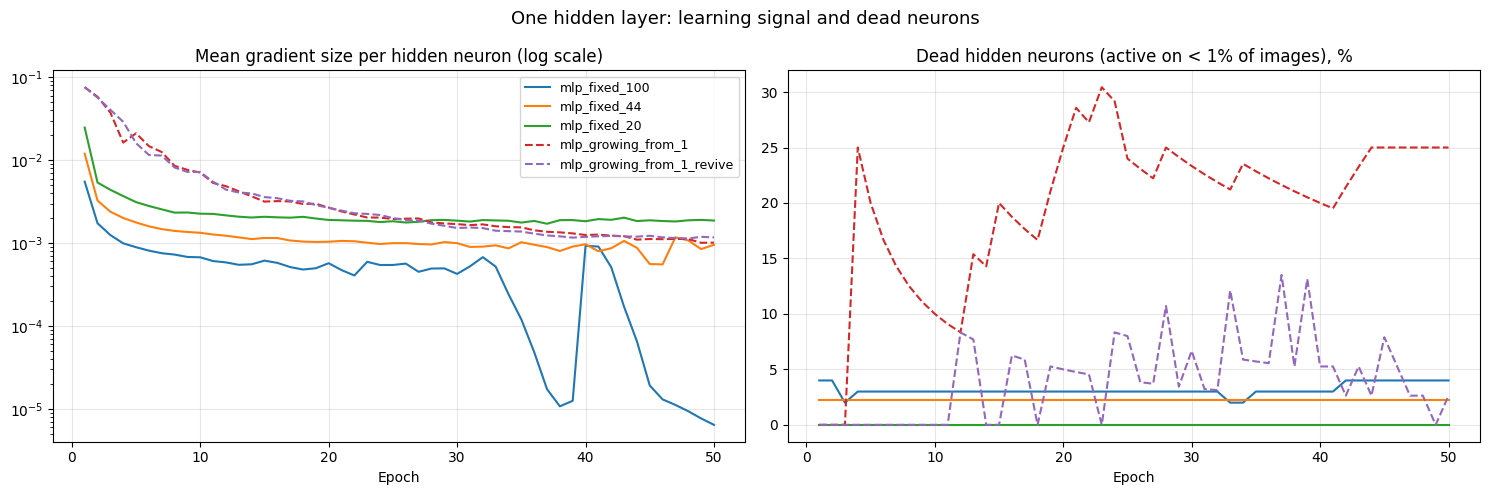

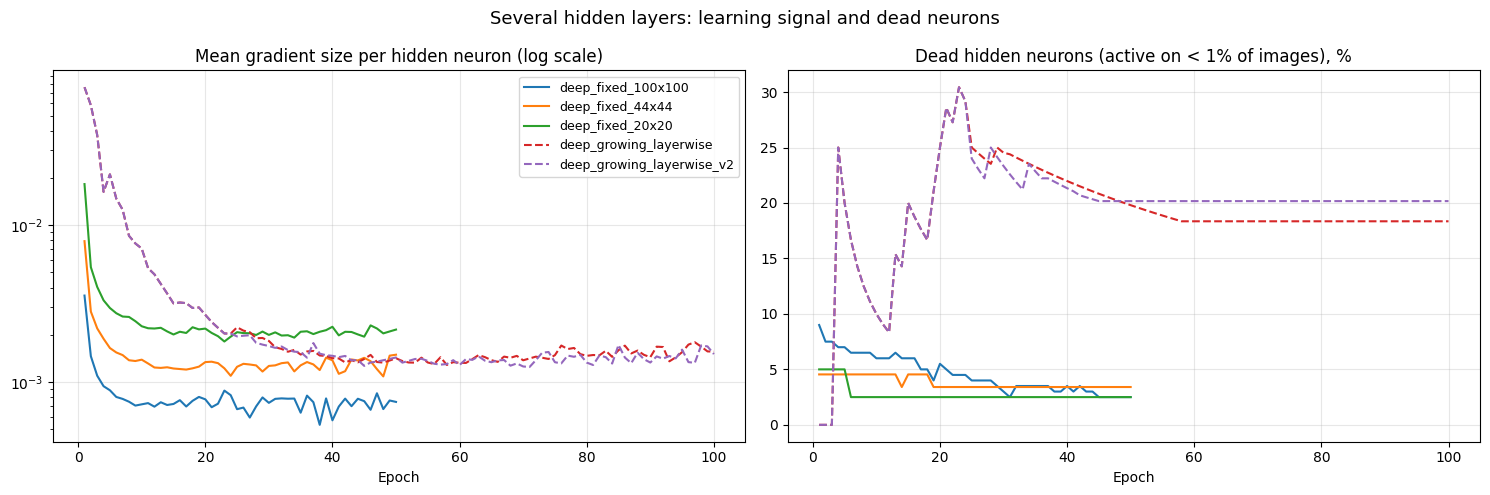

In [13]:
# ------------------------------------------------------------
# 5.6 Layer-level dynamics: gradient size and dead neurons over training
# ------------------------------------------------------------
def plot_layer_dynamics(run_names, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for name in run_names:
        ns = runs[name]["neurons"]
        hidden = ns[ns["layer"] != "output"]
        style = "--" if "growing" in name else "-"
        grad = hidden.groupby("epoch")["weight_grad_l2_norm"].mean()
        dead = hidden.groupby("epoch")["active_rate"].apply(lambda a: 100 * (a < DEAD_THRESHOLD).mean())
        axes[0].plot(grad.index, grad.values, style, label=name)
        axes[1].plot(dead.index, dead.values, style, label=name)
    axes[0].set_yscale("log")
    axes[0].set_title("Mean gradient size per hidden neuron (log scale)")
    axes[1].set_title(f"Dead hidden neurons (active on < {DEAD_THRESHOLD:.0%} of images), %")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=9)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    save_and_show(fig, filename)


plot_layer_dynamics(single_layer_runs, "One hidden layer: learning signal and dead neurons", "dynamics_single_layer.png")
plot_layer_dynamics(deep_runs, "Several hidden layers: learning signal and dead neurons", "dynamics_deep.png")


**Discussion.**

- **Gradient size.** The gradients of the growing networks start high (small network, high loss) and approach the level of the fixed 44-neuron network towards epoch 50. The gradient of the fixed 100-neuron network collapses to about $10^{-5}$ after epoch 35, the signature of the memorisation seen in Section 5.3.
- **Dead neurons, one layer.** Without revival the share of dead neurons climbs to 25–30%; with revival it fluctuates between 0 and 14% from epoch to epoch and ends at about 3% (1 of 38). The fixed networks stay between 0 and 4%.
- **Dead neurons, several layers.** In the fixed two-layer networks the share of dead neurons *decreases* during training (from 9% to 2.5% for 100+100). A dead neuron in the second layer can recover, because its inputs, the first layer's outputs, keep changing. In the layer-wise growing networks the share stays at 18–20% after the insertions, because the dead neurons are copied into every new layer (Section 5.5).

### 5.7 Weight and gradient distributions

Histograms of all first-hidden-layer weights and of the absolute values of their epoch-averaged gradients ($\log_{10}$) at epochs 1, 10, 25 and 50, read from the `.npz` snapshots.

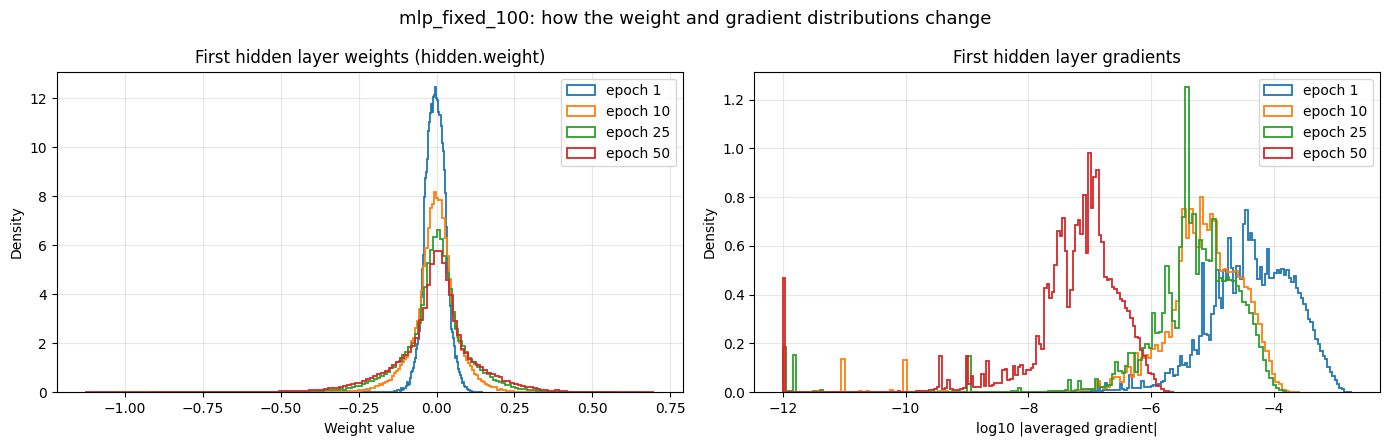

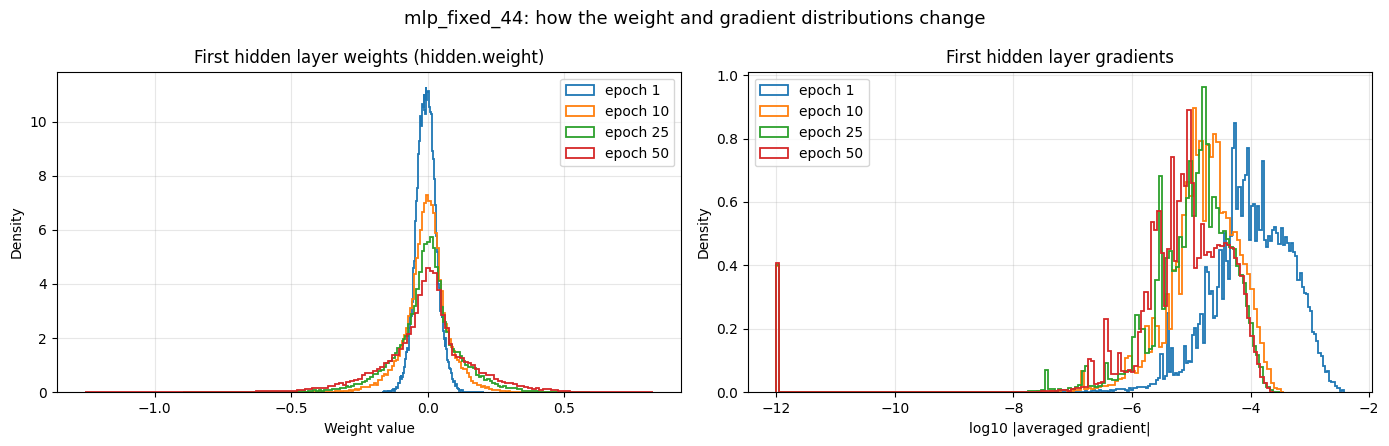

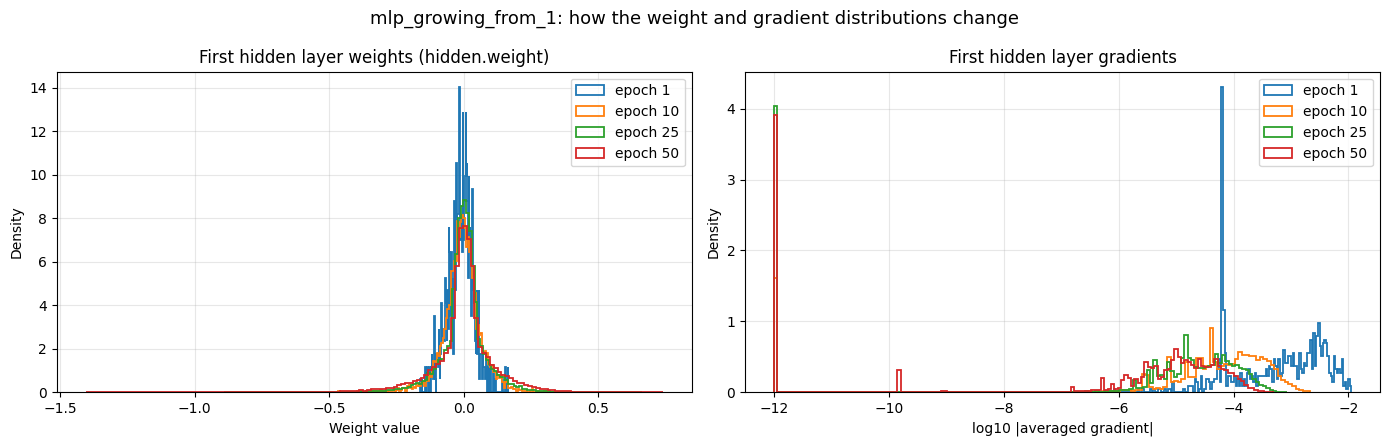

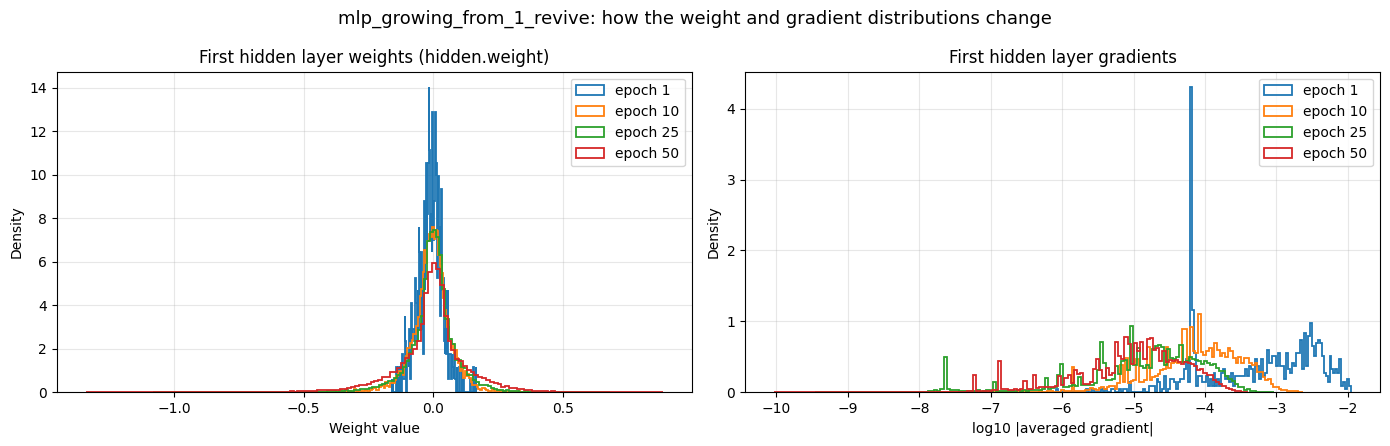

In [14]:
# ------------------------------------------------------------
# 5.7 Distributions of first-layer weights and gradients (from the .npz files)
# ------------------------------------------------------------
def plot_weight_histograms(name, epochs=(1, 10, 25, 50)):
    run_dir = runs[name]["dir"]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for epoch in epochs:
        path = os.path.join(run_dir, f"epoch_{epoch:03d}.npz")
        if not os.path.exists(path):
            continue
        data = np.load(path)
        weight_key = sorted(k for k in data.files
                            if k.startswith("param__") and k.endswith(".weight") and "output" not in k)[0]
        grad_key = weight_key.replace("param__", "grad__")
        weights = data[weight_key].ravel()
        grads = np.log10(np.abs(data[grad_key].ravel()) + 1e-12)
        axes[0].hist(weights, bins=150, histtype="step", density=True, linewidth=1.3, label=f"epoch {epoch}")
        axes[1].hist(grads, bins=150, histtype="step", density=True, linewidth=1.3, label=f"epoch {epoch}")
    axes[0].set_title(f"First hidden layer weights ({weight_key.replace('param__', '')})")
    axes[0].set_xlabel("Weight value")
    axes[1].set_title("First hidden layer gradients")
    axes[1].set_xlabel("log10 |averaged gradient|")
    for ax in axes:
        ax.set_ylabel("Density")
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(f"{name}: how the weight and gradient distributions change", fontsize=13)
    plt.tight_layout()
    save_and_show(fig, f"histograms_{name}.png")


for name in ["mlp_fixed_100", "mlp_fixed_44", "mlp_growing_from_1", "mlp_growing_from_1_revive"]:
    if name in runs:
        plot_weight_histograms(name)


**Discussion.** In every network the weight distribution widens during training and develops heavier tails: a minority of weights grows large while most remain near zero. The bulk of the gradient distribution moves from about $10^{-3}$–$10^{-2}$ at epoch 1 to about $10^{-5}$ at epoch 50, a decrease of two to three orders of magnitude. The epoch-1 histograms of the growing networks contain only 784 weights (a single neuron), which explains their irregular shape.

### 5.8 Export of results

All plots, the summary table and every run's CSV files and architecture diagrams are collected in `results_for_report.zip` (the `.npz` snapshots are excluded because of their size; they are regenerated by running the notebook). The archive is the `results/` folder of the GitHub repository.

In [15]:
# ------------------------------------------------------------
# 5.8 Export: summary, plots and CSV files in one zip (without the large .npz files)
# ------------------------------------------------------------
pack_dir = "/kaggle/working/results_for_report"
shutil.rmtree(pack_dir, ignore_errors=True)
shutil.copytree(PLOT_DIR, os.path.join(pack_dir, "plots"))
shutil.copy(os.path.join(OUT_DIR, "summary_table.csv"), pack_dir)
for name, r in runs.items():
    os.makedirs(os.path.join(pack_dir, "runs", name), exist_ok=True)
    for f in ["epoch_summary.csv", "neuron_stats.csv", "final_network.png"]:
        src = os.path.join(r["dir"], f)
        if os.path.exists(src):
            shutil.copy(src, os.path.join(pack_dir, "runs", name, f))
zip_path = shutil.make_archive("/kaggle/working/results_for_report", "zip", pack_dir)
print("Download this file from the Output panel:", zip_path)

Download this file from the Output panel: /kaggle/working/results_for_report.zip


## 6. Results and discussion

### 6.1 Main results (epoch 50)

| Exp. | Network (final) | Parameters | Loss < 0.05 at epoch | Test acc. (%) | Test loss | Train − test gap (pp) | Dead neurons (final) |
|---|---|---|---|---|---|---|---|
| 1 | 784-100-10 | 79,510 | 6 | **98.13** | **0.116** | 1.87 | 4 of 100 |
| 1 | 784-44-10 | 34,990 | 12 | 97.06 | 0.176 | 2.71 | 1 of 44 |
| 1 | 784-20-10 | 15,910 | 49 | 95.79 | 0.176 | 2.57 | 0 of 20 |
| 2 | grown to 784-44-10 | 34,990 | 44 | 97.01 | 0.125 | 1.95 | 11 of 44 |
| 2b | grown to 784-38-10 | **30,220** | 38 | 97.07 | 0.127 | 2.20 | 1 of 38 |
| 3 | 784-100-100-10 | 89,610 | 6 | 97.82 | 0.174 | 1.98 | 5 of 200 |
| 3 | 784-44-44-10 | 36,970 | 12 | 97.30 | 0.189 | 2.31 | 3 of 88 |
| 3 | 784-20-20-10 | 16,330 | 48 | 95.96 | 0.176 | 2.52 | 1 of 40 |
| 4 | grown to 784-24-29-56-10 | 21,815 | 58 | 96.29 | 0.147 | 1.74 | 20 of 109 |
| 4b | grown to 784-36-40-43-10 | 31,943 | 45 | 96.45 | 0.152 | 2.31 | 24 of 119 |

For Experiments 4 and 4b, which train for 100 epochs, the dead-neuron count is taken at epoch 100. At epoch 100 their test accuracy is 96.14% and 96.99% respectively.

### 6.2 Computational cost

| Run | Neuron-epochs (hidden layer) | Relative to fixed 44 | Wall-clock time (50 epochs) |
|---|---|---|---|
| Fixed 100 | 5,000 | 227% | 7.4 min |
| Fixed 44 | 2,200 | 100% | 7.2 min |
| Fixed 20 | 1,000 | 45% | 7.2 min |
| Growing (Exp. 2) | 1,254 | 57% | 7.3 min |
| Growing + revival (Exp. 2b) | 1,197 | 54% | 7.3 min |

*Neuron-epochs* is the sum of the hidden-layer width over all 50 epochs. It is proportional to the arithmetic performed by the hidden layer and is therefore a hardware-independent measure of computational cost. The growing networks needed little more than half the computation of the fixed 44-neuron network. This saving did **not** translate into shorter wall-clock time: on a GPU, networks of this size are limited by data loading rather than arithmetic, so all 50-epoch runs took about 7.3 minutes. The saving would matter for larger models, on CPUs, or on energy-constrained hardware.

### 6.3 Answers to the research questions

**RQ1 – Accuracy of growing networks.** Yes, for a single hidden layer. The network grown to 44 neurons reaches 97.01% test accuracy at epoch 50, against 97.06% for the fixed 44-neuron network, a difference well within run-to-run variation. The fixed network reaches a higher peak (97.51% at epoch 13), but that peak can only be identified by monitoring the test set and is followed by overfitting.

**RQ2 – Evolution of weights, gradients and activity.** New neurons start with large gradients that decay as they settle, so a growing network's average gradient remains higher than that of a fixed network of the same final size for most of training. The most important difference is in neuron activity: neurons in the growing network die far more often (25% vs. at most 4%).

**RQ3 – Overfitting.** Within 50 epochs the growing networks overfit less: their final test loss is 0.125–0.127 against 0.176 for the fixed 44- and 20-neuron networks, and the gap between training and test accuracy is smaller (1.95 and 2.20 percentage points vs. 2.71). Part of this advantage comes from the growing networks spending only 7–13 epochs at their final size, which acts like early stopping. When the layer-wise networks continue training for another 50 epochs after growth stops, they overfit in the same way.

**RQ4 – Layer-wise growth.** Inserting identity layers preserves what the network has learned: training continued without disruption after every insertion. On MNIST, however, depth does not help (single layer of 100: 98.13%; 100+100: 97.82%), and layer-wise growth is sensitive to its plateau rule. A one-epoch rule froze the first layer at 24 neurons and created a bottleneck (96.14% at epoch 100); a three-epoch average rule raised the first layer to 36 neurons and the accuracy to 96.99%.

**RQ5 – Dead neurons.** Two mechanisms were identified. Neurons can die in any network, but they die far more often in a growing network, and a dead neuron in the first hidden layer can never recover, so they accumulate. Identity-initialised layers copy every dead neuron of their parent layer, so in layer-wise growth the dead share propagates through the whole network. Testing new neurons at birth and reviving dead neurons with zero outgoing weights removes the problem (1 dead neuron out of 38) and makes growth more efficient: the target is reached with 38 instead of 44 neurons, with equal accuracy.

That neurons kept dying in almost every epoch suggests a further cause. A new Adam optimiser is created after every growth step, and Adam's first updates move every parameter by roughly the learning rate, whatever the size of its gradient [3]. Repeated large first steps may push neurons into the inactive region. This hypothesis was not tested here.

### 6.4 Limitations

- **Single seed.** Every configuration was trained once (seed 42). Differences of a few tenths of a percentage point should not be interpreted without repeated runs.
- **Dataset.** MNIST is simple enough that a single small hidden layer suffices; conclusions about depth require a harder dataset.
- **Hand-chosen thresholds.** The growth target (0.05), plateau threshold (0.005) and dead-neuron threshold (1%) were set by hand, and Experiment 4 shows that results depend on them.
- **Growth speed.** Growth is one neuron per epoch, so network size and training time are coupled; a 50-epoch budget limits single-layer growth to 50 neurons.
- **Test-set monitoring.** The test set was evaluated every epoch for reporting only. The main comparisons therefore use the fixed epoch 50, and the "best" accuracies are optimistic.

## 7. Conclusions and future work

### 7.1 Conclusions

1. A single-hidden-layer network grown from one neuron with weight preservation reaches the accuracy of a fixed network of the same final size (97.01% vs. 97.06%) using 57% of its computation, and overfits less within the same epoch budget.
2. Recording every weight, bias and gradient per epoch made a problem visible that accuracy curves hide: a quarter of the neurons in the growing network were dead.
3. Dead-neuron revival removed the problem and made growth more efficient: 38 neurons, 13.6% fewer parameters, and equal accuracy (97.07%).
4. Function-preserving identity layers make layer-wise growth possible without losing learned knowledge, but the method is sensitive to its plateau rule and propagates dead neurons into every new layer. On MNIST, depth provides no advantage.

### 7.2 Future work

- **CIFAR-10.** Repeat both problems on CIFAR-10, where additional layers are expected to matter (the planned next stage).
- **Revival in layer-wise growth.** Revive dead neurons *before* an identity layer is inserted, so that no dead neuron is copied.
- **Optimiser state.** Carry Adam's moment estimates over to the enlarged network instead of restarting the optimiser, to test the hypothesis of Section 6.3.
- **Repeated runs.** Train every configuration with several seeds and report means with confidence intervals.
- **Data-driven growth criteria.** Use the recorded gradient statistics to decide *where* and *when* to grow, as in gradient-based growth methods such as GradMax [8], and combine growth with pruning of unused neurons.